# AMR : DenseNet121 image classifier and machine-learning classifiers
**This is 2nd notebook.** It needs the outputs of **AMR_Segmentation.ipynb** on Drive (`results_final/cellpose_otsu/`): `tables/cells_all.csv`, `crops/*.zip`, `run_configuration.json`.

- **Part A (sections 12-17)**: single-cell DenseNet121 classifier (Zagajewski et al. 2023 style), all four antibiotics, all evaluation metrics, Grad-CAM, `.keras` export.
- **Part B (sections 18-25)**: machine-learning classifiers on the CSV parameters of exactly the same cells and split, SHAP, DL-vs-ML comparison, inference function, download bundle.

Run all cells in one session: Part B uses Part A's results held in memory (`S`, `meta`, `p_te`, `tid`).
Cached after the first run: `deep_learning/cache/X.npy` and `meta.csv` (delete that folder if you ever re-run Segmentation Part on different data).

## Setup

In [16]:
import subprocess, sys

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "tifffile",
        "imagecodecs",
        "cellpose<4",
        "scikit-image",
        "scipy",
        "tqdm",
        "shap",
        "lightgbm",
        "xgboost",
    ],
    check=False,
)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'tifffile', 'imagecodecs', 'cellpose<4', 'scikit-image', 'scipy', 'tqdm', 'shap', 'lightgbm', 'xgboost'], returncode=0)

In [17]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
import io, json, random, re, shutil, sys, warnings, zipfile
from datetime import datetime
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tifffile, torch
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import linear_sum_assignment
from skimage import draw
from skimage.exposure import equalize_adapthist
from skimage.feature import blob_log, graycomatrix, graycoprops, peak_local_max
from skimage.filters import threshold_otsu, unsharp_mask
from skimage.measure import label, regionprops
from skimage.morphology import disk
from skimage.segmentation import find_boundaries, relabel_sequential, watershed
from tqdm.auto import tqdm
from cellpose import models

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

In [ ]:
# =============================== SETTINGS (must match Segmentation Part) ===============================
# Folder written by Segmentation Part: "cellpose_otsu" (full run) or "cellpose_otsu_TEST" (MAX_IMAGES_PER_CLASS = 5 test run)
FOLDER = "cellpose_otsu"

RESEARCH = Path("/content/drive/MyDrive/Research")
OUT_ROOT = RESEARCH / "results_final" / FOLDER
RAW_ZIP = RESEARCH / "All Images.zip"   # only needed for the section 24 demo / consistency check
RAW_DIR = Path("/content/dataset_raw")

# ---- settings saved by Segmentation Part ----
cfg = json.loads((OUT_ROOT / "run_configuration.json").read_text())
CLASSES = cfg["classes"]
SEED = cfg["seed"]
PIXEL_SIZE_UM = cfg["pixel_size_um"]
UM2 = PIXEL_SIZE_UM**2
DIAMETER, FLOW = cfg["diameter"], cfg["flow_threshold"]
CELLPOSE_MODEL = cfg["cellpose_model"]
CELLPROB_THRESHOLD, MIN_SIZE = cfg["cellprob_threshold"], cfg["min_size"]
MIN_CELL_AREA_PX, NUC_MIN_AREA_PX = cfg["min_cell_area_px"], cfg["nuc_min_area_px"]
CROP_MARGIN = cfg["crop_margin_px"]
# not stored in run_configuration.json: copied from Segmentation Part's settings cell
GLCM_LEVELS = 32
QC_MIN_AREA_UM2, QC_MAX_AREA_UM2 = 0.25, 30.0

random.seed(SEED)
np.random.seed(SEED)
print("Output folder:", OUT_ROOT)
print(f"Segmentation Part settings: diameter={DIAMETER}, flow={FLOW}, classes={CLASSES}")

# Both frameworks share one GPU: let TensorFlow grow its memory instead of grabbing it all
import tensorflow as _tf
for _g in _tf.config.list_physical_devices("GPU"):
    _tf.config.experimental.set_memory_growth(_g, True)

cells_all = pd.read_csv(OUT_ROOT / "tables" / "cells_all.csv")
print("cells_all:", cells_all.shape)

Output folder: /content/drive/MyDrive/Research/results_final/cellpose_otsu
Part A settings: diameter=16, flow=0.4, classes=['CIP+ETOH', 'RIF+ETOH', 'GENT+ETOH', 'COAMOX+ETOH', 'WT+ETOH']
cells_all: (91117, 79)


### Helper functions copied unchanged from Segmentation Part (used by the inference code in section 24)

In [20]:
def load_raw(path):
    """Native-dtype array, H x W x C. Channel 0 = Nile Red (membrane), channel 1 = DNA."""
    arr = np.squeeze(tifffile.imread(str(path)))
    if arr.ndim != 3:
        raise ValueError(f"{Path(path).name}: unsupported TIFF shape {arr.shape}")
    if arr.shape[0] <= 8 and arr.shape[1] > 32 and arr.shape[2] > 32:
        arr = np.moveaxis(arr, 0, -1)
    elif not (arr.shape[2] <= 8 and arr.shape[0] > 32 and arr.shape[1] > 32):
        raise ValueError(f"{Path(path).name}: cannot determine channel axis from {arr.shape}")
    return arr

In [21]:
def normalize_channel(ch):
    """1-99 percentile normalisation to [0,1]; used for SEGMENTATION INPUT and display only."""
    p1, p99 = np.percentile(ch, (1, 99))
    d = (p99 - p1) if p99 > p1 else 1.0
    return np.clip((ch - p1) / d, 0, 1).astype(np.float32)

In [22]:
def clean_labels(labels, min_area):
    labels = np.asarray(labels).astype(np.int64)
    if labels.max() == 0:
        return labels.astype(np.uint16)
    small = np.bincount(labels.ravel()) < min_area
    small[0] = False
    labels = np.where(small[labels], 0, labels)
    labels, _, _ = relabel_sequential(labels)
    return labels.astype(np.uint16 if labels.max() < 65535 else np.uint32)

In [23]:
def circularity(area, perimeter):
    return float(4.0 * np.pi * area / perimeter**2) if perimeter > 0 else np.nan

In [24]:
# Cellpose is only needed for section 24 (inference), so it is loaded lazily the first time it is used.
_CP = {}
def segment_cells(mem_norm, diameter, flow):
    if "m" not in _CP:
        _CP["m"] = models.CellposeModel(gpu=torch.cuda.is_available(), model_type=CELLPOSE_MODEL)
    masks, _, _ = _CP["m"].eval(
        mem_norm,
        channels=[0, 0],
        diameter=diameter,
        min_size=MIN_SIZE,
        cellprob_threshold=CELLPROB_THRESHOLD,
        flow_threshold=flow,
    )
    return masks

In [25]:
def segment_nucleoids_otsu(cell_mask, dna_raw):
    nuc = np.zeros(cell_mask.shape, dtype=np.uint32)
    nid = 1
    for prop in regionprops(cell_mask):
        r0, c0, r1, c1 = prop.bbox
        sub_c = cell_mask[r0:r1, c0:c1] == prop.label
        sub_d = dna_raw[r0:r1, c0:c1]
        vals = sub_d[sub_c]
        if vals.size <= 20 or np.ptp(vals) <= 0:
            continue
        sub_n = ndi.binary_opening((sub_d > threshold_otsu(vals)) & sub_c, structure=disk(1))
        lab = label(sub_n)
        if lab.max() == 0:
            continue
        areas = np.bincount(lab.ravel())
        win = nuc[r0:r1, c0:c1]
        for i in np.nonzero(areas >= NUC_MIN_AREA_PX)[0]:
            if i == 0:
                continue
            win[lab == i] = nid
            nid += 1
    return nuc

In [26]:
def glcm_features(sub_memb, sub_cell):
    nan = {
        "Texture_Contrast": np.nan,
        "Texture_Correlation": np.nan,
        "Texture_Energy": np.nan,
        "Texture_Homogeneity": np.nan,
    }
    vals = sub_memb[sub_cell]
    if vals.size < 4 or vals.max() <= vals.min():
        return nan
    lo, hi = vals.min(), vals.max()
    q = np.zeros(sub_memb.shape, dtype=np.uint8)
    q[sub_cell] = 1 + np.floor((vals - lo) / (hi - lo + 1e-6) * (GLCM_LEVELS - 1)).astype(np.uint8)
    g = graycomatrix(
        q,
        distances=[1],
        angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
        levels=GLCM_LEVELS + 1,
        symmetric=True,
        normed=False,
    )[1:, 1:]
    sums = g.sum(axis=(0, 1), keepdims=True).astype(np.float64)
    if sums.sum() == 0:
        return nan
    g = g / np.where(sums == 0, 1, sums)
    return {
        "Texture_Contrast": float(graycoprops(g, "contrast").mean()),
        "Texture_Correlation": float(graycoprops(g, "correlation").mean()),
        "Texture_Energy": float(graycoprops(g, "energy").mean()),
        "Texture_Homogeneity": float(graycoprops(g, "homogeneity").mean()),
    }

In [27]:
def intensity_stats(px, prefix):
    px = px.astype(np.float64)
    return {
        f"{prefix}_Mean": px.mean(),
        f"{prefix}_Median": float(np.median(px)),
        f"{prefix}_Min": px.min(),
        f"{prefix}_Max": px.max(),
        f"{prefix}_Std": px.std(),
        f"{prefix}_Variance": px.var(),
        f"{prefix}_Sum": px.sum(),
    }

In [28]:
NUC_KEYS = [
    "Count",
    "Total_Area_um2",
    "Mean_Length_um",
    "Mean_Width_um",
    "Mean_Circularity",
    "Mean_Eccentricity",
    "Mean_DNA_Intensity",
    "Max_DNA_Intensity",
    "Integrated_DNA_Intensity",
    "Cell_Area_Ratio",
    "Contrast",
    "Offset_Frac",
    "Max_Separation_um",
]

In [29]:
def nucleoid_summary(props, sub_nuc, sub_cell, sub_dna, cell, cell_area_px, y0, x0):
    if len(props) == 0:
        out = {f"Nuc_{k}": np.nan for k in NUC_KEYS}
        out.update(
            Nuc_Count=0,
            Nuc_Total_Area_um2=0.0,
            Nuc_Cell_Area_Ratio=0.0,
            Nuc_Integrated_DNA_Intensity=0.0,
        )
        return out
    total_px = float(sum(p.area for p in props))
    nuc_pix = sub_nuc > 0
    rest = sub_cell & ~nuc_pix
    contrast = (
        (float(sub_dna[nuc_pix].mean()) / float(sub_dna[rest].mean()))
        if rest.any() and sub_dna[rest].mean() > 0
        else np.nan
    )
    cy, cx = cell.centroid[0] - y0, cell.centroid[1] - x0
    ny = sum(p.area * p.centroid[0] for p in props) / total_px
    nx = sum(p.area * p.centroid[1] for p in props) / total_px
    half = max(cell.major_axis_length / 2.0, 1e-6)
    cents = np.array([p.centroid for p in props])
    sep = (
        float(
            np.max(
                np.hypot(
                    cents[:, None, 0] - cents[None, :, 0], cents[:, None, 1] - cents[None, :, 1]
                )
            )
        )
        * PIXEL_SIZE_UM
        if len(props) > 1
        else 0.0
    )
    return {
        "Nuc_Count": len(props),
        "Nuc_Total_Area_um2": total_px * UM2,
        "Nuc_Mean_Length_um": float(np.mean([p.major_axis_length for p in props])) * PIXEL_SIZE_UM,
        "Nuc_Mean_Width_um": float(np.mean([p.minor_axis_length for p in props])) * PIXEL_SIZE_UM,
        "Nuc_Mean_Circularity": float(
            np.nanmean([circularity(p.area, p.perimeter) for p in props])
        ),
        "Nuc_Mean_Eccentricity": float(np.mean([p.eccentricity for p in props])),
        "Nuc_Mean_DNA_Intensity": float(np.mean([p.mean_intensity for p in props])),
        "Nuc_Max_DNA_Intensity": float(np.max([p.max_intensity for p in props])),
        "Nuc_Integrated_DNA_Intensity": float(sub_dna[nuc_pix].sum()),
        "Nuc_Cell_Area_Ratio": total_px / cell_area_px if cell_area_px > 0 else np.nan,
        "Nuc_Contrast": contrast,
        "Nuc_Offset_Frac": float(np.hypot(ny - cy, nx - cx) / half),
        "Nuc_Max_Separation_um": sep,
    }

# Part A: deep-learning image Resistant / Susceptible classifier
- Resistant phenotype = untreated cells (`WT+ETOH`). Susceptible phenotype = antibiotic-treated cells (CIP, RIF, GENT, COAMOX), all four antibiotics.
- Per cell: Nile Red -> red channel, DNA -> green channel, per-channel histogram equalisation **inside the cell mask**, background zeroed, zero-padded (downscaled if larger) to 64x64.
- DenseNet121 classifier, on-the-fly augmentation, class balancing. Splits are by **image** (or by experiment if `Experiment_ID` is parsed), never by cell, to avoid leakage.
- Model 1 `amr_susceptibility_model.keras`: resistant vs susceptible, conditioned on the antibiotic.
- Model 2 `amr_treatment_identifier.keras`: which of CIP / RIF / GENT / COAMOX / WT an image belongs to.
- Probabilities are temperature-calibrated on the validation set. Explainability: **Grad-CAM** (DenseNet). SHAP for the parameter-based models is in Part A.

In [ ]:
import subprocess, sys

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap", "lightgbm"], check=False)
assert "OUT_ROOT" in globals() and "cells_all" in globals(), "Run Segmentation Part (sections 0-6) first."

import io, json, zipfile, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tifffile, shap
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn import metrics as skm
from sklearn.calibration import calibration_curve
from scipy.optimize import minimize_scalar
from skimage.exposure import equalize_hist
from skimage.transform import resize
from skimage.measure import regionprops
from skimage.segmentation import find_boundaries
import lightgbm as lgb
from tqdm.auto import tqdm

In [31]:
# ---- settings ----
DL = OUT_ROOT / "deep_learning"
for sub in [
    "models",
    "metrics",
    "cache",
    "figures/individual",
    "figures/gradcam",
    "figures/shap",
    "predictions",
]:
    (DL / sub).mkdir(parents=True, exist_ok=True)
IMG, NET_IN = (
    64,
    128,
)  # stored crop size / size fed to DenseNet (upsampled inside the model for finer Grad-CAM)
TREAT = [c.split("+")[0] for c in CLASSES]  # CIP RIF GENT COAMOX WT
CTRL = "WT"
ABX = [t for t in TREAT if t != CTRL]
EPOCHS, BATCH, LR = 10, 128, 1e-4
USE_IMAGENET = True  # False = train DenseNet from scratch
USE_QC_CELLS_ONLY = True  # drop border-touching / size-outlier cells (QC_Pass)
SPLIT_FRAC = (0.70, 0.15, 0.15)  # train / val / test (by image)
TAB_FEATURES = [
    "Area_um2",
    "Length_um",
    "Width_um",
    "Aspect_Ratio",
    "Circularity",
    "Eccentricity",
    "Solidity",
    "Extent",
    "Perimeter_um",
    "Nuc_Count",
    "Nuc_Total_Area_um2",
    "Nuc_Mean_Length_um",
    "Nuc_Mean_Width_um",
    "Nuc_Mean_Circularity",
    "Nuc_Cell_Area_Ratio",
    "Nuc_Contrast",
    "Nuc_Offset_Frac",
    "Nuc_Max_Separation_um",
]  # shape + nucleoid geometry only (no raw intensities: batch-sensitive)
tf.keras.utils.set_random_seed(SEED)
print("GPU:", tf.config.list_physical_devices("GPU"), "| antibiotics:", ABX)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | antibiotics: ['CIP', 'RIF', 'GENT', 'COAMOX']


* TensorFlow detected one GPU, so GPU acceleration is available.
* The four antibiotic classes are CIP, RIF, GENT and COAMOX; WT is the untreated control.
* The model is configured for 64×64 cell crops, DenseNet121 with ImageNet weights, image/experiment-level splitting, and a 70/15/15 train/validation/test target. 
* These settings define the experiment; GPU detection alone does not demonstrate model quality.

## A1. Building single-cell dataset

In [32]:
def prep_cell(raw2, mask):
    """raw2: (2,h,w) original dtype [NileRed, DNA]; mask: bool (h,w).
    Per-channel histogram equalisation inside the mask, background = 0, zero-pad to IMG x IMG (downscale if larger). Returns uint8 HxWx3 (R=NileRed, G=DNA).
    """
    chans = []
    for c in range(2):
        ch = raw2[c].astype(np.float32)
        ok = mask.sum() > 4 and ch[mask].max() > ch[mask].min()
        chans.append((equalize_hist(ch, nbins=256, mask=mask) if ok else np.zeros_like(ch)) * mask)
    rgb = np.stack([chans[0], chans[1], np.zeros_like(chans[0])], -1)
    h, w = rgb.shape[:2]
    if max(h, w) > IMG:
        s = IMG / max(h, w)
        rgb = resize(
            rgb,
            (max(1, round(h * s)), max(1, round(w * s)), 3),
            order=1,
            anti_aliasing=True,
            preserve_range=True,
        )
        h, w = rgb.shape[:2]
    out = np.zeros((IMG, IMG, 3), np.float32)
    y0, x0 = (IMG - h) // 2, (IMG - w) // 2
    out[y0 : y0 + h, x0 : x0 + w] = rgb
    return (out * 255).round().astype(np.uint8)

In [33]:
def assign_splits(df):
    rng = np.random.RandomState(SEED)
    split = pd.Series("train", index=df.index)
    has_exp = "Experiment_ID" in df and df["Experiment_ID"].replace("", np.nan).nunique() >= 3
    if has_exp:  # hold out whole experiments, as in the paper
        exps = sorted(df["Experiment_ID"].dropna().unique())
        rng.shuffle(exps)
        n_te, n_va = max(1, round(SPLIT_FRAC[2] * len(exps))), max(
            1, round(SPLIT_FRAC[1] * len(exps))
        )
        split[df.Experiment_ID.isin(exps[:n_te])] = "test"
        split[df.Experiment_ID.isin(exps[n_te : n_te + n_va])] = "val"
    else:  # hold out whole images, per treatment class
        for cls, g in df.groupby("Treatment_Class"):
            imgs = sorted(g.Image_ID.unique())
            rng.shuffle(imgs)
            n_te, n_va = max(1, round(SPLIT_FRAC[2] * len(imgs))), max(
                1, round(SPLIT_FRAC[1] * len(imgs))
            )
            split[g.index[g.Image_ID.isin(imgs[:n_te])]] = "test"
            split[g.index[g.Image_ID.isin(imgs[n_te : n_te + n_va])]] = "val"
    print(
        "split by:",
        (
            "Experiment_ID"
            if has_exp
            else "Image_ID (per class)  <- if images of one experiment share batch effects, fill METADATA_REGEX/Experiment_ID"
        ),
    )
    return split

In [34]:
X_PATH, M_PATH = DL / "cache" / "X.npy", DL / "cache" / "meta.csv"
if X_PATH.exists() and M_PATH.exists():
    X = np.load(X_PATH)
    meta = pd.read_csv(M_PATH)
    print("loaded cache:", X.shape)
else:
    meta = cells_all.copy()
    if USE_QC_CELLS_ONLY:
        meta = meta[meta.QC_Pass]
    meta = meta[meta.Raw_Crop_Path.fillna("").astype(str).str.len() > 0].reset_index(drop=True)
    X = np.zeros((len(meta), IMG, IMG, 3), np.uint8)
    for zname, g in meta.groupby("Crop_Zip"):
        with zipfile.ZipFile(OUT_ROOT / "crops" / zname) as z:
            for i, rp, lp in tqdm(
                list(zip(g.index, g.Raw_Crop_Path, g.Label_Crop_Path)), desc=zname
            ):
                raw = tifffile.imread(io.BytesIO(z.read(rp)))
                msk = tifffile.imread(io.BytesIO(z.read(lp)))[0] > 0
                X[i] = prep_cell(raw, msk)
    meta["Split"] = assign_splits(meta)
    np.save(X_PATH, X)
    meta.to_csv(M_PATH, index=False)
meta["Treat"] = meta.Treatment_Class.str.split("+").str[0]
display(pd.crosstab(meta.Treat, meta.Split))

loaded cache: (74474, 64, 64, 3)


Split,test,train,val
Treat,,,
CIP,1862,10647,2504
COAMOX,917,5267,1178
GENT,1198,7148,1503
RIF,2978,15153,2743
WT,3584,14830,2962


* The cache contains 74,474 RGB cell crops of size 64×64.
* The table gives the number of cells per treatment in each split.
* Train, validation and test cells are not independently sampled at cell level: the split function attempts to hold out whole experiments when enough `Experiment_ID` values exist, otherwise whole images per treatment.
* The counts differ from a perfect 70/15/15 split because splitting is done by groups/images and the number of images per class varies.

## A2. Models

In [35]:
def build_model(n_out, use_abx, name):
    img = keras.Input((IMG, IMG, 3), name="image")
    x = layers.Rescaling(1 / 255.0)(img)
    x = layers.RandomFlip("horizontal_and_vertical")(x)  # augmentation: active in training only
    x = layers.RandomRotation(0.5, fill_mode="constant", fill_value=0.0)(x)
    x = layers.RandomTranslation(0.08, 0.08, fill_mode="constant", fill_value=0.0)(x)
    x = layers.GaussianNoise(0.02)(x)
    x = layers.Resizing(NET_IN, NET_IN)(x)
    x = layers.Normalization(mean=[0.485, 0.456, 0.406], variance=[0.229**2, 0.224**2, 0.225**2])(x)
    base = keras.applications.DenseNet121(
        include_top=False, weights="imagenet" if USE_IMAGENET else None, input_tensor=x
    )
    f = layers.GlobalAveragePooling2D()(base.output)
    inputs = [img]
    if use_abx:
        ab = keras.Input((len(ABX),), name="abx")
        inputs.append(ab)
        f = layers.Concatenate()([f, layers.Dense(16, activation="relu")(ab)])
    f = layers.Dropout(0.3)(layers.Dense(128, activation="relu")(f))
    out = (
        layers.Dense(1, activation="sigmoid", name="p_susceptible")(f)
        if n_out == 1
        else layers.Dense(n_out, activation="softmax", name="p_treatment")(f)
    )
    for l in base.layers:
      if isinstance(l, layers.BatchNormalization):
        l.trainable = False
    return keras.Model(inputs, out, name=name)

In [36]:
def make_ds(inputs, y, w, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((inputs, y, w))
    if shuffle:
        ds = ds.shuffle(min(len(y), 20000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(
        lambda xi, yy, ww: ({**xi, "image": tf.cast(xi["image"], tf.float32)}, yy, ww)
    )
    return ds.prefetch(tf.data.AUTOTUNE)

In [37]:
def fit(model, tr, va, path, monitor, mode):
    cb = [
        keras.callbacks.EarlyStopping(monitor, mode=mode, patience=6, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
        keras.callbacks.ModelCheckpoint(str(path), monitor=monitor, mode=mode, save_best_only=True),
    ]
    return model.fit(tr, validation_data=va, epochs=EPOCHS, callbacks=cb).history

In [38]:
def onehot(A, n):
    return np.eye(n, dtype="float32")[A]

### Model 1. Susceptibility model (Resistant vs Susceptible, per antibiotic)
* For antibiotic *a*: resistant = untreated WT cells, susceptible = *a*-treated cells.
* WT cells are split once and reused for every antibiotic.
* Sample weights balance the two classes within each antibiotic.

In [39]:
def sus_index(split_name):
    idx, y, A = [], [], []
    wt = meta.index[(meta.Treat == CTRL) & (meta.Split == split_name)].values
    for k, ab in enumerate(ABX):
        s = meta.index[(meta.Treat == ab) & (meta.Split == split_name)].values
        idx += [wt, s]
        y += [np.zeros(len(wt)), np.ones(len(s))]
        A += [np.full(len(wt) + len(s), k)]
    return np.concatenate(idx), np.concatenate(y).astype("float32"), np.concatenate(A)

In [40]:
def sus_weights(y, A):
    w = np.ones(len(y), "float32")
    for k in range(len(ABX)):
        for c in (0, 1):
            m = (A == k) & (y == c)
            if m.any():
                w[m] = (A == k).sum() / (2.0 * m.sum())
    return w

In [41]:
S = {s: sus_index(s) for s in ["train", "val", "test"]}
def sus_ds(s, shuffle):
    idx, y, A = S[s]
    return make_ds({"image": X[idx], "abx": onehot(A, len(ABX))}, y, sus_weights(y, A), shuffle)

In [42]:
sus = build_model(1, True, "amr_susceptibility")
sus.compile(
    keras.optimizers.Adam(LR),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
    ],
)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [43]:
SUS_PATH = DL / "models" / "amr_susceptibility_model.keras"
hist_sus = fit(sus, sus_ds("train", True), sus_ds("val", False), SUS_PATH, "val_auc", "max")

Epoch 1/10
762/762 ━━━━━━━━━━━━━━━━━━━━ 450s 518ms/step - accuracy: 0.8302 - auc: 0.9148 - loss: 0.3644 - precision: 0.7589 - recall: 0.8306 - val_accuracy: 0.7552 - val_auc: 0.9152 - val_loss: 0.4440 - val_precision: 0.6293 - val_recall: 0.9474 - learning_rate: 1.0000e-04
Epoch 2/10
762/762 ━━━━━━━━━━━━━━━━━━━━ 386s 506ms/step - accuracy: 0.8727 - auc: 0.9488 - loss: 0.2868 - precision: 0.8082 - recall: 0.8854 - val_accuracy: 0.7677 - val_auc: 0.9126 - val_loss: 0.4490 - val_precision: 0.6471 - val_recall: 0.9248 - learning_rate: 1.0000e-04
Epoch 3/10
762/762 ━━━━━━━━━━━━━━━━━━━━ 389s 510ms/step - accuracy: 0.8835 - auc: 0.9568 - loss: 0.2641 - precision: 0.8217 - recall: 0.8975 - val_accuracy: 0.7318 - val_auc: 0.9208 - val_loss: 0.4674 - val_precision: 0.6032 - val_recall: 0.9673 - learning_rate: 1.0000e-04
Epoch 4/10
762/762 ━━━━━━━━━━━━━━━━━━━━ 386s 506ms/step - accuracy: 0.8906 - auc: 0.9616 - loss: 0.2501 - precision: 0.8293 - recall: 0.9076 - val_accuracy: 0.7458 - val_auc: 0.9

* Training AUC rises steadily from 0.915 to 0.976 and training accuracy reaches 0.915. These training metrics use class-balancing sample weights.
* Validation is noisy in epochs 1 to 4 (AUC bouncing between 0.90 and 0.92), then improves once the learning rate was halved at epoch 5. The best validation AUC is 0.955 at epoch 7.
* Validation recall stays high (0.92 to 0.97) while precision is lower (0.60 to 0.77), meaning the model prefers calling cells "susceptible". This bias reappears in the test results.
* Each epoch took about 6.5 minutes. Early stopping (patience 6) did not trigger, so the run used all 10 epochs.

In [44]:
idx, y, A = S["train"]
sub = np.random.RandomState(0).choice(len(idx), 3000, replace=False)
p = sus.predict({"image": X[idx[sub]], "abx": onehot(A[sub], len(ABX))}, batch_size=256, verbose=0).ravel()
print("train-subset accuracy in inference mode:", ((p >= 0.5) == y[sub]).mean())

train-subset accuracy in inference mode: 0.8626666666666667


* On 3,000 training cells, with the model in inference mode, accuracy is 0.863. This is close to the ~0.91 training-log accuracy (which is weighted).
* It confirms training and inference behave consistently now.

In [45]:
pd.DataFrame(hist_sus).to_csv(DL / "metrics" / "history_susceptibility.csv", index=False)

### Model 2. Treatment identifier (CIP / RIF / GENT / COAMOX / WT)

In [46]:
TID = {t: i for i, t in enumerate(TREAT)}


def tid_ds(s, shuffle):
    idx = meta.index[meta.Split == s].values
    y = meta.loc[idx, "Treat"].map(TID).values.astype("int32")
    cnt = np.bincount(y, minlength=len(TREAT)).astype(float)
    w = (len(y) / (len(TREAT) * np.maximum(cnt, 1)))[y].astype("float32")
    return idx, y, make_ds({"image": X[idx]}, y, w, shuffle)

In [47]:
_, _, tr_t = tid_ds("train", True)
_, _, va_t = tid_ds("val", False)
tid = build_model(len(TREAT), False, "amr_treatment_identifier")
tid.compile(
    keras.optimizers.Adam(LR),
    loss="sparse_categorical_crossentropy",
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)
TID_PATH = DL / "models" / "amr_treatment_identifier.keras"
hist_tid = fit(tid, tr_t, va_t, TID_PATH, "val_accuracy", "max")
pd.DataFrame(hist_tid).to_csv(DL / "metrics" / "history_treatment_identifier.csv", index=False)

Epoch 1/10
415/415 ━━━━━━━━━━━━━━━━━━━━ 248s 534ms/step - accuracy: 0.6165 - loss: 0.9326 - val_accuracy: 0.6612 - val_loss: 0.8566 - learning_rate: 1.0000e-04
Epoch 2/10
415/415 ━━━━━━━━━━━━━━━━━━━━ 211s 508ms/step - accuracy: 0.7173 - loss: 0.7334 - val_accuracy: 0.7149 - val_loss: 0.7683 - learning_rate: 1.0000e-04
Epoch 3/10
415/415 ━━━━━━━━━━━━━━━━━━━━ 209s 504ms/step - accuracy: 0.7435 - loss: 0.6592 - val_accuracy: 0.6678 - val_loss: 0.7923 - learning_rate: 1.0000e-04
Epoch 4/10
415/415 ━━━━━━━━━━━━━━━━━━━━ 209s 504ms/step - accuracy: 0.7650 - loss: 0.6139 - val_accuracy: 0.6806 - val_loss: 0.7819 - learning_rate: 1.0000e-04
Epoch 5/10
415/415 ━━━━━━━━━━━━━━━━━━━━ 211s 509ms/step - accuracy: 0.7719 - loss: 0.5874 - val_accuracy: 0.7497 - val_loss: 0.6743 - learning_rate: 1.0000e-04
Epoch 6/10
415/415 ━━━━━━━━━━━━━━━━━━━━ 210s 505ms/step - accuracy: 0.7853 - loss: 0.5530 - val_accuracy: 0.7249 - val_loss: 0.7121 - learning_rate: 1.0000e-04
Epoch 7/10
415/415 ━━━━━━━━━━━━━━━━━━━━ 

* Training accuracy climbs from 0.62 to 0.81 and validation accuracy from 0.66 to about 0.77, with validation loss falling from 0.86 to 0.62.
* Both curves are still improving at epoch 10, and the learning rate never needed reducing, so this model is not fully converged. More epochs would probably help.
* The task is harder than susceptible versus resistant because five visually similar classes must be separated, which is why accuracy is lower.

## A3. Calibration, final models, inference config

In [48]:
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def predict_sus(model, idx, A):
    return model.predict(
        {"image": X[idx], "abx": onehot(A, len(ABX))}, batch_size=256, verbose=0
    ).ravel()

In [49]:
iv, yv, Av = S["val"]
pv = predict_sus(sus, iv, Av)
T_CAL = float(
    minimize_scalar(
        lambda t: skm.log_loss(
            yv, sigmoid(logit(pv) / t), sample_weight=sus_weights(yv, Av), labels=[0, 1]
        ),
        bounds=(0.2, 10),
        method="bounded",
    ).x
)
print(f"temperature scaling T = {T_CAL:.3f}")

temperature scaling T = 0.948


* Temperature scaling rescales the model's logits so probabilities match observed frequencies on the validation set.
* T is very close to 1, so the raw probabilities were already close to calibrated on validation; T slightly below 1 sharpens them a little.
* The calibration on the test set looks worse because the test set has a different class balance from the one used for weighting and fitting.

In [50]:
sus.save(SUS_PATH)
tid.save(TID_PATH)  # final (best-weights) models, .keras format
(DL / "models" / "amr_inference_config.json").write_text(
    json.dumps(
        {
            "img_size": IMG,
            "abx_order": ABX,
            "treatment_classes": TREAT,
            "control_class": CTRL,
            "temperature": T_CAL,
            "tab_features": TAB_FEATURES,
            "cellpose_model": CELLPOSE_MODEL,
            "diameter": DIAMETER,
            "flow_threshold": FLOW,
            "pixel_size_um": PIXEL_SIZE_UM,
            "preprocessing": "NileRed->R, DNA->G, per-channel histogram equalisation inside mask, background 0, zero-pad/downscale to 64x64, uint8",
        },
        indent=2,
    )
)

887

* The output `887` is the result of the save call in this notebook/runtime, not a performance metric.
* The model files are written to the configured model directory.

In [51]:
chk = keras.models.load_model(SUS_PATH)
idx_c = S["test"][0][:64]
assert np.allclose(
    chk.predict({"image": X[idx_c], "abx": onehot(S["test"][2][:64], len(ABX))}, verbose=0).ravel(),
    predict_sus(sus, idx_c, S["test"][2][:64]),
    atol=1e-4,
)
print("saved:", SUS_PATH.name, "|", TID_PATH.name, "| reload check OK")

saved: amr_susceptibility_model.keras | amr_treatment_identifier.keras | reload check OK


* Both the susceptibility and treatment-identification `.keras` files were saved and reloaded successfully.
* The small prediction check verifies that the saved model can be loaded and called; it does not measure predictive performance.

## A4. Evaluation on the held-out test images

In [52]:
def ece(y, p, n=10):
    b = np.minimum((p * n).astype(int), n - 1)
    e = 0.0
    for i in range(n):
        m = b == i
        if m.any():
            e += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(e)

In [53]:
def binary_metrics(y, p, thr=0.5):
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = skm.confusion_matrix(y, yh, labels=[0, 1]).ravel()
    return {
        "Accuracy": skm.accuracy_score(y, yh),
        "Balanced_Accuracy": skm.balanced_accuracy_score(y, yh),
        "Precision": skm.precision_score(y, yh, zero_division=0),
        "Recall": skm.recall_score(y, yh, zero_division=0),
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "F1": skm.f1_score(y, yh, zero_division=0),
        "MCC": skm.matthews_corrcoef(y, yh),
        "Kappa": skm.cohen_kappa_score(y, yh),
        "ROC_AUC": skm.roc_auc_score(y, p),
        "PR_AUC": skm.average_precision_score(y, p),
        "Brier": skm.brier_score_loss(y, p),
        "LogLoss": skm.log_loss(y, p, labels=[0, 1]),
        "ECE": ece(y, p),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
    }

In [54]:
it, yt, At = S["test"]
p_raw = predict_sus(sus, it, At)
p_te = sigmoid(logit(p_raw) / T_CAL)
overall = binary_metrics(yt, p_te)
per_abx = pd.DataFrame(
    {ab: binary_metrics(yt[At == k], p_te[At == k]) for k, ab in enumerate(ABX)}
).T
pd.Series(overall).to_csv(DL / "metrics" / "susceptibility_overall.csv")
per_abx.to_csv(DL / "metrics" / "susceptibility_per_antibiotic.csv")
display(pd.Series(overall).round(4).to_frame("test").T)
display(per_abx.round(3))

thr_grid = np.linspace(0.05, 0.95, 91)
thr_df = pd.DataFrame(
    [
        {
            "thr": t,
            **{
                k: v
                for k, v in binary_metrics(yt, p_te, t).items()
                if k in ("Accuracy", "Precision", "Recall", "F1")
            },
        }
        for t in thr_grid
    ]
)
thr_df.to_csv(DL / "metrics" / "threshold_sweep.csv", index=False)

,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,MCC,Kappa,ROC_AUC,PR_AUC,Brier,LogLoss,ECE,TP,FP,TN,FN
test,0.8505,0.8732,0.7032,0.9386,0.8078,0.804,0.7059,0.6872,0.9545,0.9201,0.1064,0.3432,0.1315,6528.0,2755.0,11581.0,427.0


,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,MCC,Kappa,ROC_AUC,PR_AUC,Brier,LogLoss,ECE,TP,FP,TN,FN
CIP,0.854,0.877,0.716,0.951,0.804,0.817,0.719,0.700,0.959,0.933,0.104,0.335,0.130,1770.0,701.0,2883.0,92.0
RIF,0.837,0.845,0.760,0.936,0.754,0.839,0.692,0.677,0.941,0.936,0.116,0.372,0.118,2786.0,880.0,2704.0,192.0
GENT,0.920,0.936,0.772,0.968,0.904,0.859,0.814,0.804,0.986,0.964,0.059,0.204,0.094,1160.0,343.0,3241.0,38.0
COAMOX,0.792,0.827,0.494,0.885,0.768,0.634,0.547,0.505,0.905,0.694,0.145,0.459,0.193,812.0,831.0,2753.0,105.0


* This is the principal binary test-set evaluation for DenseNet121. 
* Accuracy is 0.8505 and balanced accuracy is 0.8732. 
* Precision is 0.7032 and recall is 0.9386: the model catches most cells labelled susceptible, but a larger share of its susceptible calls are false positives. 
* Specificity is 0.8078, F1 is 0.8040, MCC is 0.7059 and Cohen's kappa is 0.6872, indicating useful but imperfect agreement.
* ROC-AUC is 0.9545, showing strong ranking discrimination across thresholds; PR-AUC should be interpreted relative to the positive-class prevalence.
* Brier score, log loss and ECE assess probability quality rather than thresholded classification alone.
* TP/FP/TN/FN are the raw confusion counts.

In [55]:
ti, yti, _ = tid_ds("test", False)
p_tid = tid.predict({"image": X[ti]}, batch_size=256, verbose=0)
yh_tid = p_tid.argmax(1)
cm_tid = skm.confusion_matrix(yti, yh_tid, labels=range(len(TREAT)))
prf = skm.precision_recall_fscore_support(yti, yh_tid, labels=range(len(TREAT)), zero_division=0)
tid_report = pd.DataFrame(
    {"Precision": prf[0], "Recall": prf[1], "F1": prf[2], "Support": prf[3]}, index=TREAT
)

In [56]:
img_p = (
    pd.DataFrame(p_tid, columns=TREAT)
    .assign(Image_ID=meta.loc[ti, "Image_ID"].values, True_=meta.loc[ti, "Treat"].values)
    .groupby(["Image_ID", "True_"])
    .mean()
    .reset_index()
)

In [57]:
img_p["Pred"] = img_p[TREAT].idxmax(axis=1)
img_acc = float((img_p.Pred == img_p.True_).mean())
tid_report.to_csv(DL / "metrics" / "treatment_identifier_report.csv")
img_p.to_csv(DL / "metrics" / "treatment_identifier_image_level.csv", index=False)
print(
    f"treatment identifier: cell accuracy {skm.accuracy_score(yti, yh_tid):.3f} | image-level accuracy {img_acc:.3f} ({len(img_p)} test images)"
)
display(tid_report.round(3))

treatment identifier: cell accuracy 0.777 | image-level accuracy 0.919 (235 test images)


,Precision,Recall,F1,Support
CIP,0.854,0.740,0.793,1862
RIF,0.893,0.698,0.783,2978
GENT,0.743,0.841,0.789,1198
COAMOX,0.577,0.662,0.617,917
WT,0.744,0.869,0.802,3584


* Single cells are identified correctly 78% of the time. Averaging the cells of one image gives 92% image-level accuracy, because individual errors cancel out.
* This image-level readout matches how a population would be judged in practice.
* COAMOX is the hardest class (F1 0.62), consistent with the susceptibility results.

In [58]:
R = dict(
    h=hist_sus,
    y=yt,
    p=p_te,
    A=At,
    overall=overall,
    per_abx=per_abx,
    thr=thr_df,
    cm_tid=cm_tid,
    tid_report=tid_report,
)

## A5. One plot per metric + final grid

In [59]:
C_R, C_I, C_S = "#d62728", "#e6b800", "#1f77b4"

def _cm(ax, cm, labels, title, frac=False):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1 if frac else None)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j,
                i,
                f"{cm[i, j]:.2f}" if frac else f"{int(cm[i, j])}",
                ha="center",
                va="center",
                fontsize=9,
                color="white" if cm[i, j] > (0.5 if frac else cm.max() / 2) else "black",
            )
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)

In [60]:
def p_loss(ax, R):
    ax.plot(R["h"]["loss"], label="train")
    ax.plot(R["h"]["val_loss"], label="val")
    ax.set(xlabel="epoch", ylabel="loss", title="Training loss")
    ax.legend()
    ax.grid(alpha=0.3)

In [61]:
def p_acc(ax, R):
    ax.plot(R["h"]["accuracy"], label="train")
    ax.plot(R["h"]["val_accuracy"], label="val")
    ax.set(xlabel="epoch", ylabel="accuracy", title="Training accuracy")
    ax.legend()
    ax.grid(alpha=0.3)

In [62]:
def p_auc(ax, R):
    ax.plot(R["h"]["auc"], label="train")
    ax.plot(R["h"]["val_auc"], label="val")
    ax.set(xlabel="epoch", ylabel="AUC", title="Training AUC")
    ax.legend()
    ax.grid(alpha=0.3)

In [63]:
def p_cm_counts(ax, R):
    o = R["overall"]
    _cm(
        ax,
        np.array([[o["TN"], o["FP"]], [o["FN"], o["TP"]]]),
        ["Resistant", "Susceptible"],
        "Confusion matrix (cells)",
    )

In [64]:
def p_cm_norm(ax, R):
    o = R["overall"]
    c = np.array([[o["TN"], o["FP"]], [o["FN"], o["TP"]]], float)
    _cm(
        ax,
        c / c.sum(1, keepdims=True),
        ["Resistant", "Susceptible"],
        "Confusion matrix (row-normalised)",
        frac=True,
    )

In [65]:
def p_roc(ax, R):
    f, t, _ = skm.roc_curve(R["y"], R["p"])
    ax.plot(f, t, lw=2.5, label=f"all (AUC {R['overall']['ROC_AUC']:.3f})")
    for k, ab in enumerate(ABX):
        m = R["A"] == k
        f, t, _ = skm.roc_curve(R["y"][m], R["p"][m])
        ax.plot(f, t, lw=1.2, label=f"{ab} ({R['per_abx'].loc[ab, 'ROC_AUC']:.3f})")
    ax.plot([0, 1], [0, 1], "k:")
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

In [66]:
def p_pr(ax, R):
    pr, rc, _ = skm.precision_recall_curve(R["y"], R["p"])
    ax.plot(rc, pr, lw=2.5, label=f"all (AP {R['overall']['PR_AUC']:.3f})")
    for k, ab in enumerate(ABX):
        m = R["A"] == k
        pr, rc, _ = skm.precision_recall_curve(R["y"][m], R["p"][m])
        ax.plot(rc, pr, lw=1.2, label=f"{ab} ({R['per_abx'].loc[ab, 'PR_AUC']:.3f})")
    ax.set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve", ylim=(0, 1.02))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

In [67]:
def p_calib(ax, R):
    fr, mp = calibration_curve(R["y"], R["p"], n_bins=10, strategy="quantile")
    ax.plot(mp, fr, "o-")
    ax.plot([0, 1], [0, 1], "k:")
    ax.set(
        xlabel="Mean predicted P(susceptible)",
        ylabel="Observed fraction susceptible",
        title=f"Calibration (ECE {R['overall']['ECE']:.3f}, Brier {R['overall']['Brier']:.3f})",
    )
    ax.grid(alpha=0.3)

In [68]:
def p_hist(ax, R):
    b = np.linspace(0, 1, 41)
    ax.hist(
        R["p"][R["y"] == 0],
        b,
        alpha=0.6,
        color=C_R,
        label="true resistant (untreated)",
        density=True,
    )
    ax.hist(
        R["p"][R["y"] == 1],
        b,
        alpha=0.6,
        color=C_S,
        label="true susceptible (treated)",
        density=True,
    )
    ax.set(xlabel="P(susceptible)", ylabel="density", title="Confidence distribution")
    ax.legend(fontsize=8)

In [69]:
def p_scores(ax, R):
    ks = [
        "Accuracy",
        "Balanced_Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1",
        "MCC",
        "Kappa",
        "ROC_AUC",
        "PR_AUC",
    ]
    v = [R["overall"][k] for k in ks]
    b = ax.barh(ks[::-1], v[::-1], color=C_S)
    for r, x in zip(b, v[::-1]):
        ax.text(
            max(x, 0) + 0.01, r.get_y() + r.get_height() / 2, f"{x:.3f}", va="center", fontsize=8
        )
    ax.set(xlim=(min(0, min(v)), 1.12), title="Test-set scores (R vs S, thr 0.5)")
    ax.grid(alpha=0.3, axis="x")

In [70]:
def p_per_abx(ax, R):
    ks = ["Accuracy", "F1", "ROC_AUC", "MCC"]
    w = 0.2
    for i, k in enumerate(ks):
        ax.bar(
            np.arange(len(ABX)) + (i - 1.5) * w, R["per_abx"][k].values.astype(float), w, label=k
        )
    ax.set_xticks(range(len(ABX)))
    ax.set_xticklabels(ABX)
    ax.set(ylim=(0, 1.1), title="Per-antibiotic performance")
    ax.legend(ncol=4, fontsize=8, loc="upper center")
    ax.grid(alpha=0.3, axis="y")

In [71]:
def p_cov(ax, R):
    d = np.linspace(0, 0.49, 50)
    yh = (R["p"] >= 0.5).astype(int)
    cov, acc = [], []
    for t in d:
        k = np.abs(R["p"] - 0.5) >= t
        cov.append(k.mean())
        acc.append((yh == R["y"])[k].mean())
    ax.plot(d, acc, label="accuracy of confident cells")
    ax.plot(d, cov, label="fraction of cells kept")
    ax.set(xlabel="|P(S) - 0.5| cut-off", title="Accuracy vs. confidence cut-off", ylim=(0, 1.02))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

In [72]:
def p_calls(ax, R):
    labs, rows = [], []
    for k, ab in enumerate(ABX):
        for nm, c in (("treated", 1), ("WT ctrl", 0)):
            pk = R["p"][(R["A"] == k) & (R["y"] == c)]
            rows.append([100 * (pk < 0.5).mean(), 100 * (pk >= 0.5).mean()])
            labs.append(f"{ab}\n{nm}")
    rows = np.array(rows)
    bt = np.zeros(len(rows))
    for j, (n, c) in enumerate(zip(["Resistant", "Susceptible"], [C_R, C_S])):
        ax.bar(labs, rows[:, j], bottom=bt, color=c, label=n)
        bt += rows[:, j]
    ax.set(ylabel="% of cells", title="Predicted call per group (test)")
    ax.tick_params(axis="x", labelsize=7)
    ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.15))

In [73]:
def p_tid_cm(ax, R):
    c = R["cm_tid"].astype(float)
    _cm(
        ax,
        c / np.maximum(c.sum(1, keepdims=True), 1),
        TREAT,
        "Treatment identifier (row-normalised)",
        frac=True,
    )

In [74]:
def p_tid_prf(ax, R):
    d = R["tid_report"]
    for i, k in enumerate(["Precision", "Recall", "F1"]):
        ax.bar(np.arange(len(d)) + (i - 1) * 0.27, d[k].values, 0.27, label=k)
    ax.set_xticks(range(len(d)))
    ax.set_xticklabels(d.index)
    ax.set(ylim=(0, 1.1), title="Treatment identifier: per-class scores")
    ax.legend(ncol=3, fontsize=8, loc="upper center")
    ax.grid(alpha=0.3, axis="y")

In [75]:
def p_thr(ax, R):
    d = R["thr"]
    for k in ["Accuracy", "Precision", "Recall", "F1"]:
        ax.plot(d.thr, d[k], label=k)
    ax.set(xlabel="decision threshold on P(S)", title="Threshold sweep", ylim=(0, 1.02))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

In [76]:
PLOTS = [
    ("training_loss", p_loss),
    ("training_accuracy", p_acc),
    ("training_auc", p_auc),
    ("confusion_counts", p_cm_counts),
    ("confusion_normalised", p_cm_norm),
    ("roc", p_roc),
    ("precision_recall", p_pr),
    ("calibration", p_calib),
    ("confidence_distribution", p_hist),
    ("scores", p_scores),
    ("per_antibiotic", p_per_abx),
    ("coverage_accuracy", p_cov),
    ("call_composition", p_calls),
    ("treatment_confusion", p_tid_cm),
    ("treatment_prf", p_tid_prf),
    ("threshold_sweep", p_thr),
]

In [77]:
for i, (n, f) in enumerate(PLOTS, 1):
    fig, ax = plt.subplots(figsize=(6.5, 5.2))
    f(ax, R)
    fig.tight_layout()
    fig.savefig(DL / "figures/individual" / f"{i:02d}_{n}.png", dpi=200)
    plt.close(fig)

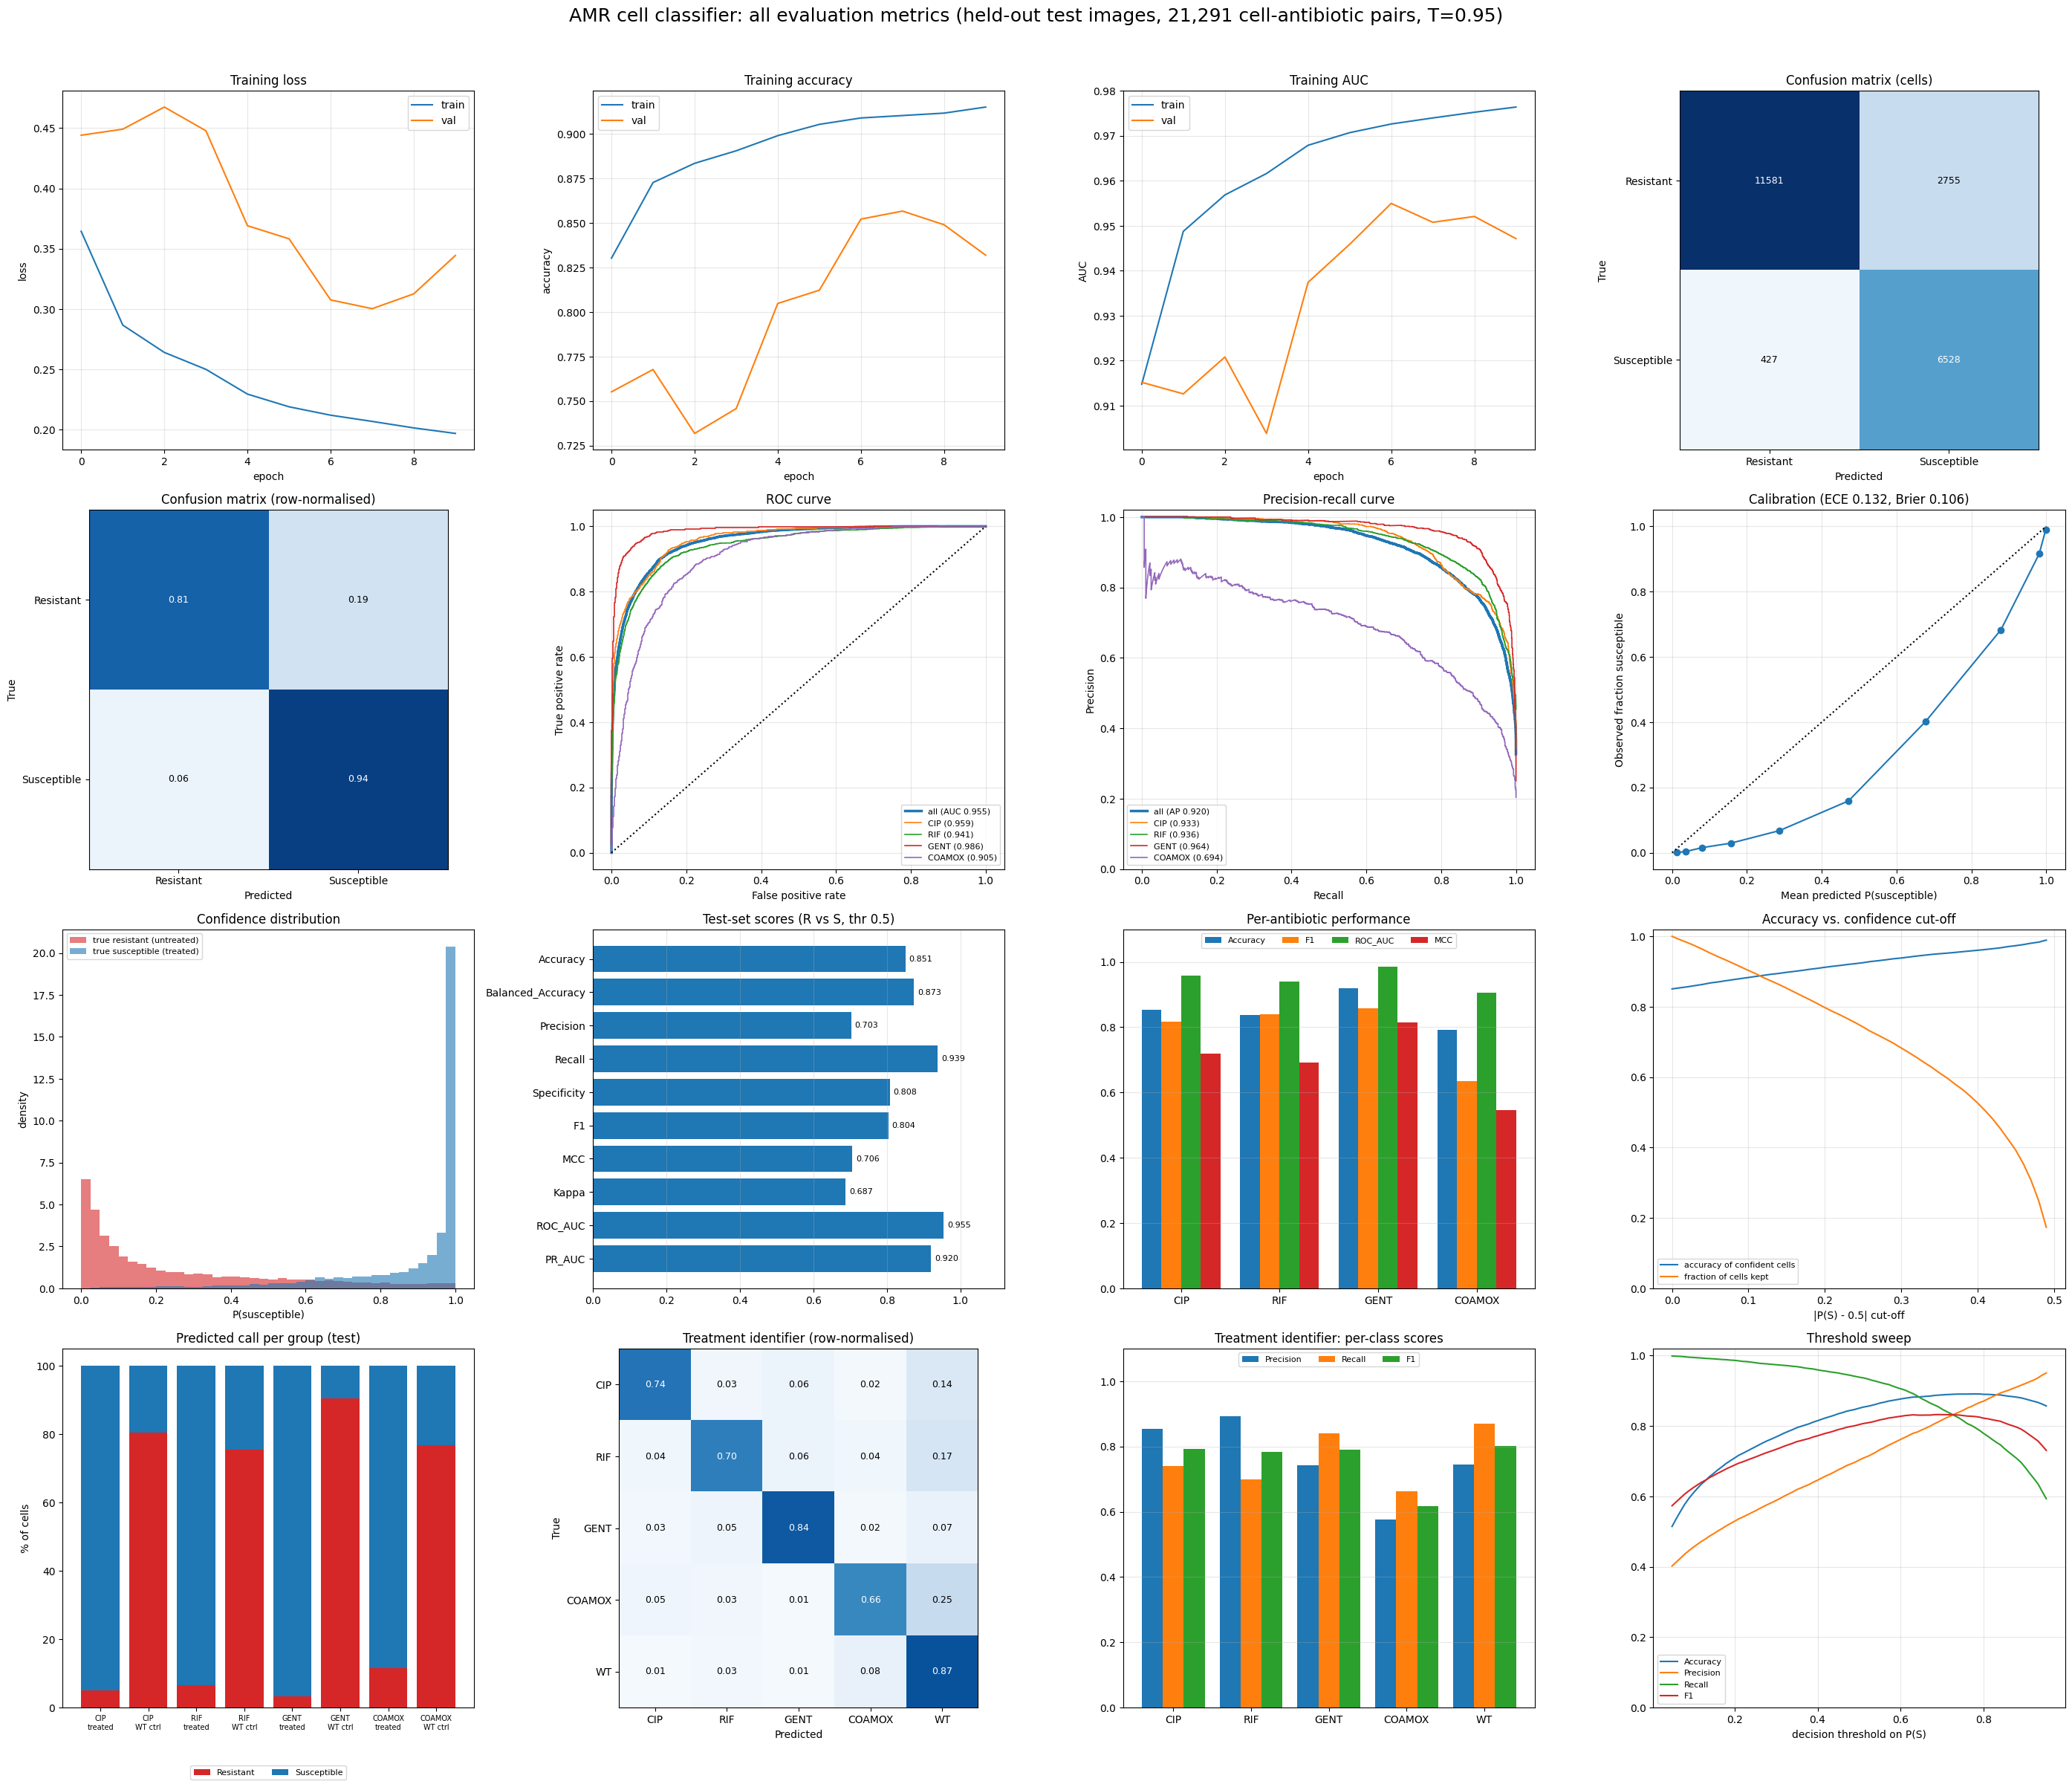

In [78]:
fig = plt.figure(figsize=(28, 24))
for i, (n, f) in enumerate(PLOTS, 1):
    f(fig.add_subplot(4, 4, i), R)
fig.suptitle(
    f"AMR cell classifier: all evaluation metrics (held-out test images, {len(yt):,} cell-antibiotic pairs, T={T_CAL:.2f})",
    fontsize=18,
    y=0.995,
)
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(DL / "figures" / "evaluation_grid.png", dpi=200)
fig.savefig(DL / "figures" / "evaluation_grid.pdf")
plt.show()

**Interpretation:**
- **Training loss, accuracy, AUC:** training curves keep improving; validation improves later and noisily, peaking around epochs 7 to 8, then dips slightly. A moderate gap (train AUC 0.976, val 0.947) points to mild overfitting.
- **Confusion matrices (counts and row-normalised):** 94% of treated cells are called susceptible, but 19% of WT cells are also wrongly called susceptible.
ROC and precision-recall curves: the pooled curve (AUC 0.955) is good. GENT is highest (0.986) and COAMOX lowest (0.905); the COAMOX precision-recall curve (purple) falls fastest.
- **Calibration (ECE 0.132):** the curve lies below the diagonal in the middle range, so the model is overconfident in saying "susceptible". One likely reason is that training weighted both classes equally, whereas the test set is only 33% susceptible. Temperature scaling cannot correct that shift.
- **Confidence distribution:** most treated cells are given probabilities near 1 and most WT cells near 0, with a long tail of WT cells scored high; those tail cells are the false positives.
- **Test-set score bars:** the same numbers as In [54].
- **Per-antibiotic bars:** performance ranks GENT > CIP ≈ RIF > COAMOX.
- **Accuracy against confidence cut-off:** keeping only confident cells raises accuracy from 0.85 towards 0.98, at the cost of discarding many cells.
- **Predicted call per group:** treated cells are called susceptible 88% to 97% of the time, while WT controls are called resistant only 75% to 90% of the time (GENT best, RIF worst).
- **Treatment identifier confusion and per-class scores:** WT and COAMOX are confused (25% of COAMOX is called WT), as are RIF and WT (17%).
- **Threshold sweep:** F1 peaks near a threshold of about 0.65 to 0.7, not 0.5. Raising the threshold would trade a little recall for more precision.

## A6. Explainability: Grad-CAM

In [79]:
def make_gradcam_model(model):
    return keras.Model(
        model.inputs, [model.get_layer("relu").output, model.output]
    )  # 'relu' = last DenseNet feature map

In [80]:
def gradcam(gm, img_u8, abx_k=None, cls=1):
    """Heat map (IMG x IMG, 0..1) of the evidence for P(susceptible) (cls=1) or P(resistant) (cls=0) for the susceptibility model;
    for the treatment model pass abx_k=None and cls = class index."""
    x = tf.convert_to_tensor(img_u8[None].astype("float32"))
    inp = {"image": x}
    if abx_k is not None:
        inp["abx"] = tf.one_hot([abx_k], len(ABX))
    with tf.GradientTape() as tape:
        conv, pred = gm(inp, training=False)
        score = (pred[:, 0] if cls == 1 else 1 - pred[:, 0]) if abx_k is not None else pred[:, cls]
    g = tape.gradient(score, conv)
    w = tf.reduce_mean(g, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], -1))[0].numpy()
    cam = resize(cam, (IMG, IMG), order=1) * (img_u8.sum(-1) > 0)
    return cam / cam.max() if cam.max() > 0 else cam

In [81]:
gm_sus = make_gradcam_model(sus)
pred_lab = (p_te >= 0.5).astype(int)
corr = pred_lab == yt

In [82]:
def pick(k, cond, n, hi=True):
    ids = np.where((At == k) & cond)[0]
    conf = np.abs(p_te[ids] - 0.5)
    return ids[np.argsort(-conf if hi else conf)[:n]]

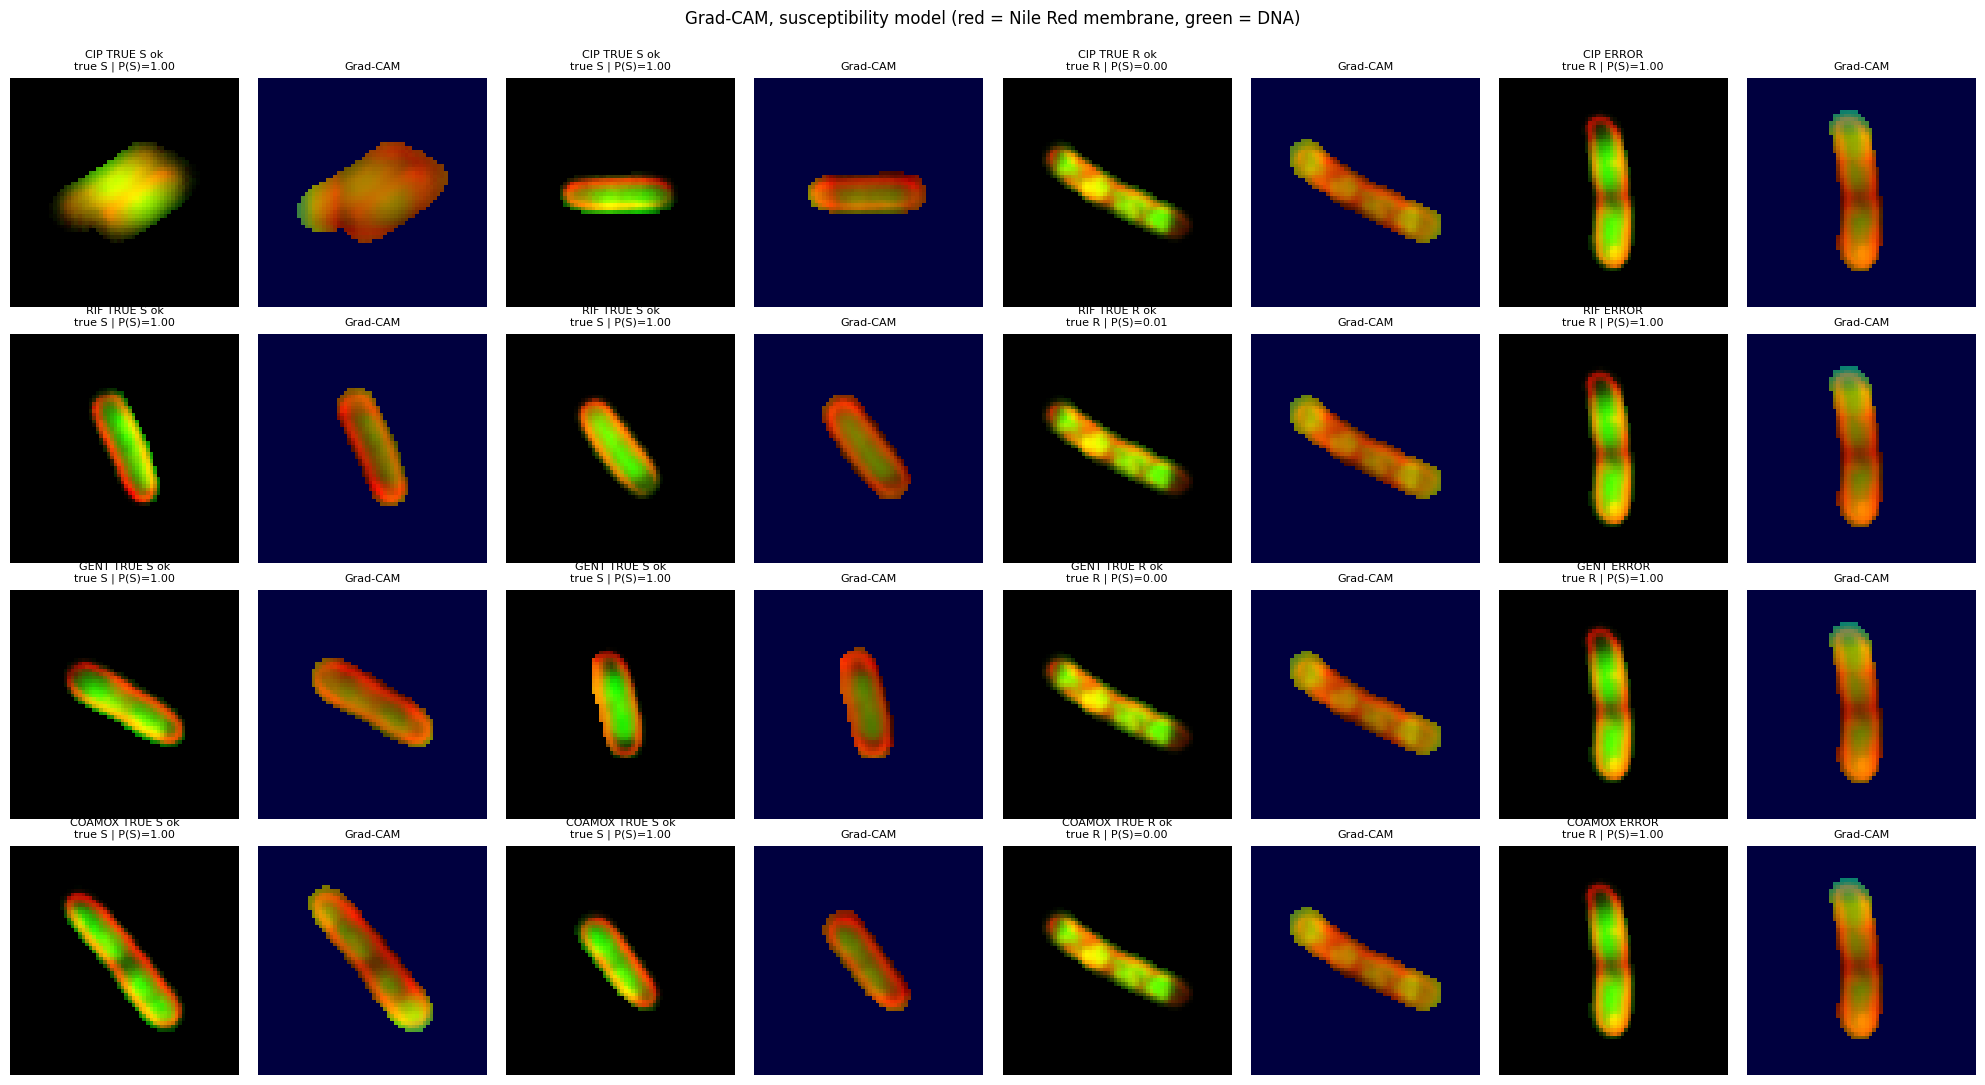

In [83]:
fig, axes = plt.subplots(len(ABX), 8, figsize=(20, 2.7 * len(ABX)))
for k, ab in enumerate(ABX):
    sel = (
        list(pick(k, corr & (yt == 1), 2))
        + list(pick(k, corr & (yt == 0), 1))
        + list(pick(k, ~corr, 1))
    )
    tags = ["TRUE S ok", "TRUE S ok", "TRUE R ok", "ERROR"]
    for j in range(4):
        a1, a2 = axes[k, 2 * j], axes[k, 2 * j + 1]
        a1.axis("off")
        a2.axis("off")
        if j >= len(sel):
            continue
        i = sel[j]
        img = X[it[i]]
        cam = gradcam(gm_sus, img, k, cls=1 if p_te[i] >= 0.5 else 0)
        a1.imshow(img)
        a1.set_title(
            f"{ab} {tags[j]}\ntrue {'S' if yt[i] else 'R'} | P(S)={p_te[i]:.2f}", fontsize=8
        )
        a2.imshow(img)
        a2.imshow(cam, cmap="jet", alpha=0.5)
        a2.set_title("Grad-CAM", fontsize=8)
fig.suptitle("Grad-CAM, susceptibility model (red = Nile Red membrane, green = DNA)", y=1.0)
fig.tight_layout()
fig.savefig(DL / "figures/gradcam" / "gradcam_susceptibility.png", dpi=200)
plt.show()

**Each row is one antibiotic. For each of four cells the left image is the input (red = membrane, green = DNA) and the right image overlays the Grad-CAM heat map (where the model looked).**

* Columns 1 to 2 are correctly called susceptible cells (P(S) about 1.0), column 3 is a correctly called WT cell (P(S) about 0), and column 4 is an error.
* The WT cells in columns 3 and 4 are the same in every row, because WT is the shared "resistant" class.
* The heat maps spread across the whole cell and its outline, rather than a small spot. The model uses overall shape, membrane and DNA distribution, not one specific feature.
* The error cell is a long WT cell with several separate DNA clusters, called susceptible with P(S) = 1.00. It is worth looking at by eye.

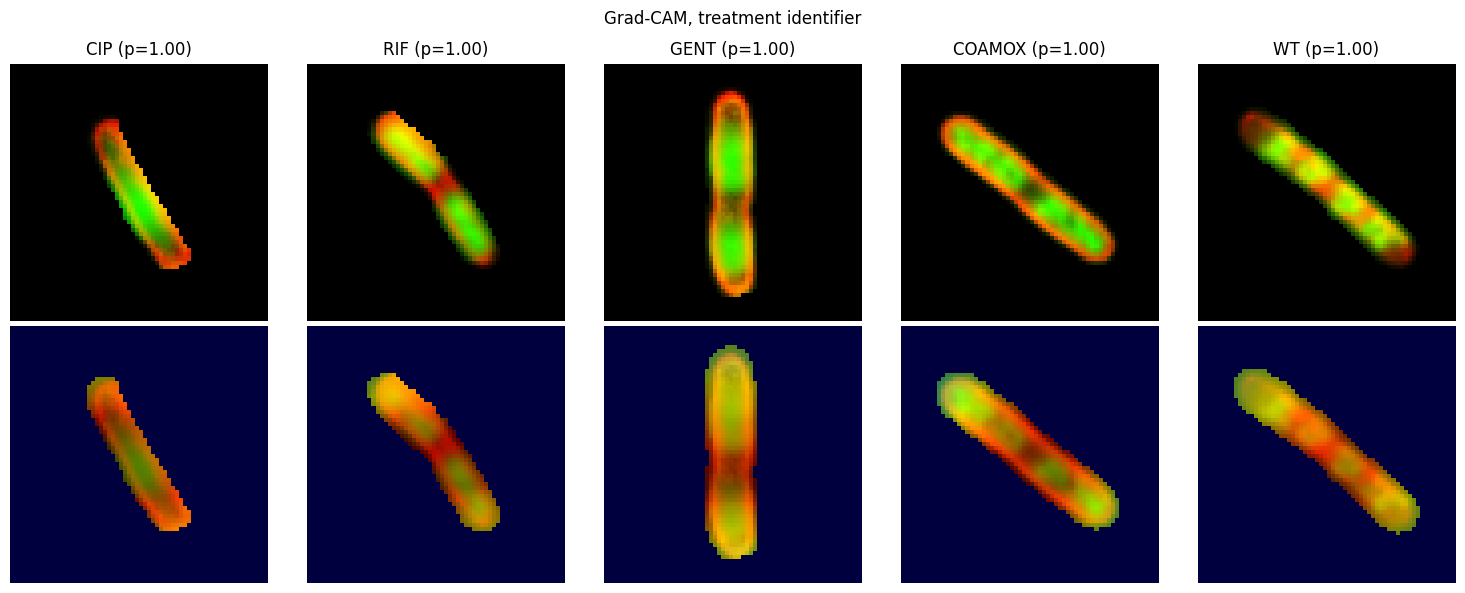

In [84]:
gm_tid = make_gradcam_model(tid)
fig, axes = plt.subplots(2, len(TREAT), figsize=(3 * len(TREAT), 6))
for c, t in enumerate(TREAT):
    ids = np.where((yti == c) & (yh_tid == c))[0]
    if len(ids) == 0:
        axes[0, c].axis("off")
        axes[1, c].axis("off")
        continue
    i = ids[np.argmax(p_tid[ids, c])]
    img = X[ti[i]]
    axes[0, c].imshow(img)
    axes[0, c].set_title(f"{t} (p={p_tid[i, c]:.2f})")
    axes[1, c].imshow(img)
    axes[1, c].imshow(gradcam(gm_tid, img, None, c), cmap="jet", alpha=0.5)
    axes[0, c].axis("off")
    axes[1, c].axis("off")
fig.suptitle("Grad-CAM, treatment identifier")
fig.tight_layout()
fig.savefig(DL / "figures/gradcam" / "gradcam_treatment.png", dpi=200)
plt.show()

* One confidently correct example per class (p = 1.00).
* The heat maps again cover the whole cell, with stronger weight on the cell body and the membrane edge.
* The cell shapes agree with what Part A found: COAMOX and WT cells are long, while CIP, RIF and GENT cells in these examples are shorter or more compact.

# PART B: machine-learning classification on the CSV parameters (same cells, same split as the images)
**What and why**
- **Row-level match between images and CSV.** Every cell has one row in `cells_all.csv` and one 64x64 crop; the split table (`Split`) was made once, by image, and both the DenseNet and every ML model use exactly those rows. Section 18 verifies this (crops re-derived from the saved zips must equal the cached image tensors; no image appears in two splits; saved split manifest).
- **labels:** untreated `WT` = resistant, antibiotic-treated = susceptible, one classifier per antibiotic (all four)
- **Feature sets (ablation):** A = morphology + nucleoid geometry, B = A + texture + scale-free intensity ratios (default), C = B + raw intensities (batch-sensitive, shown only as an ablation).
- **Model sweep** on the validation set (HistGB, LightGBM, XGBoost, MLP), Platt calibration, grouped (by image) cross-validation for the winner, permutation importance + SHAP.
- **Comparison:** DL vs ML vs their average, on identical test rows, with bootstrap confidence intervals resampled by image, McNemar test, and an image-level (population).
- **Inference:** one function: image -> segmentation -> the same parameters as the CSV -> treatment detection -> R/S percentages from DL, ML and ensemble.

In [ ]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GroupKFold
from sklearn.inspection import permutation_importance
from scipy.stats import chi2
import lightgbm as lgb

try:
    import xgboost as xgb
except Exception:
    xgb = None
assert (
    "S" in globals() and "meta" in globals() and "p_te" in globals()
), "Run Part A (sections 12-17) first."

In [86]:
ML = OUT_ROOT / "machine_learning"
for sub in ["models", "metrics", "figures/individual", "figures/shap", "predictions"]:
    (ML / sub).mkdir(parents=True, exist_ok=True)
FEATURE_SET = "B_plus_texture_ratios"  # "A_morphology_nucleoid" | "B_plus_texture_ratios" | "C_plus_raw_intensity"
RUN_CV, CV_FOLDS, N_BOOT = True, 5, 200
MODELS = ["HistGB", "LightGBM"] + (["XGBoost"] if xgb else []) + ["MLP"]
TREE_SHAP_OK = ("LightGBM", "XGBoost")

In [87]:

MORPH = [
    "Area_um2",
    "Length_um",
    "Width_um",
    "Perimeter_um",
    "Aspect_Ratio",
    "Circularity",
    "Eccentricity",
    "Solidity",
    "Extent",
]

In [88]:
NUC = [
    "Nuc_Count",
    "Nuc_Total_Area_um2",
    "Nuc_Mean_Length_um",
    "Nuc_Mean_Width_um",
    "Nuc_Mean_Circularity",
    "Nuc_Mean_Eccentricity",
    "Nuc_Cell_Area_Ratio",
    "Nuc_Contrast",
    "Nuc_Offset_Frac",
    "Nuc_Max_Separation_um",
]

In [89]:
TEX = ["Texture_Contrast", "Texture_Correlation", "Texture_Energy", "Texture_Homogeneity"]
DERIVED = [
    "DNA_CV",
    "NR_CV",
    "DNA_Max_over_Mean",
    "NR_Max_over_Mean",
    "DNA_to_NR_Mean_Ratio",
    "Nuc_Intensity_Ratio",
]  # scale-free, less batch-sensitive

In [90]:
RAWINT = [
    "NileRed_Intensity_Mean",
    "NileRed_Intensity_Median",
    "NileRed_Intensity_Std",
    "NileRed_Intensity_Max",
    "DNA_Intensity_Mean",
    "DNA_Intensity_Median",
    "DNA_Intensity_Std",
    "DNA_Intensity_Max",
    "Nuc_Mean_DNA_Intensity",
    "Nuc_Max_DNA_Intensity",
]

In [91]:
FEATURE_SETS = {
    "A_morphology_nucleoid": MORPH + NUC,
    "B_plus_texture_ratios": MORPH + NUC + TEX + DERIVED,
    "C_plus_raw_intensity": MORPH + NUC + TEX + DERIVED + RAWINT,
}
FEATS = FEATURE_SETS[FEATURE_SET]

In [92]:
def add_derived(df):
    d = df.copy()
    z = lambda c: d[c].replace(0, np.nan)
    d["DNA_CV"] = d["DNA_Intensity_Std"] / z("DNA_Intensity_Mean")
    d["NR_CV"] = d["NileRed_Intensity_Std"] / z("NileRed_Intensity_Mean")
    d["DNA_Max_over_Mean"] = d["DNA_Intensity_Max"] / z("DNA_Intensity_Mean")
    d["NR_Max_over_Mean"] = d["NileRed_Intensity_Max"] / z("NileRed_Intensity_Mean")
    d["DNA_to_NR_Mean_Ratio"] = d["DNA_Intensity_Mean"] / z("NileRed_Intensity_Mean")
    d["Nuc_Intensity_Ratio"] = d["Nuc_Max_DNA_Intensity"] / z("DNA_Intensity_Mean")
    d["Nuc_Count"] = d["Nuc_Count"].fillna(0)
    return d.replace([np.inf, -np.inf], np.nan)

In [93]:
feat = add_derived(meta)
missing = [c for c in FEATURE_SETS["C_plus_raw_intensity"] if c not in feat.columns]
assert not missing, f"columns missing from cells_all: {missing}"
print(f"feature set {FEATURE_SET}: {len(FEATS)} parameters | models: {MODELS}")

feature set B_plus_texture_ratios: 29 parameters | models: ['HistGB', 'LightGBM', 'XGBoost', 'MLP']


* The CSV-based models use 29 features: cell shape, nucleoid geometry, membrane texture and scale-free intensity ratios (raw intensities are left out because they are sensitive to imaging conditions).
* Four model families are compared in this run.

## B1. Image <-> CSV matching checks and split manifest

In [94]:
def verify_alignment(n=25):
    rs = np.random.RandomState(SEED)
    ids = rs.choice(len(meta), min(n, len(meta)), replace=False)
    zs = {}
    for i in ids:
        r = meta.loc[i]
        z = zs.setdefault(r.Crop_Zip, zipfile.ZipFile(OUT_ROOT / "crops" / r.Crop_Zip))
        raw = tifffile.imread(io.BytesIO(z.read(r.Raw_Crop_Path)))
        msk = tifffile.imread(io.BytesIO(z.read(r.Label_Crop_Path)))[0] > 0
        assert np.array_equal(
            prep_cell(raw, msk), X[i]
        ), f"image tensor and CSV row differ at row {i} ({r.Cell_UID})"
    return len(ids)

In [95]:
assert len(X) == len(meta) == len(feat)
print("image tensor <-> CSV row check passed for", verify_alignment(), "random cells")
assert (
    meta.groupby("Image_ID").Split.nunique() == 1
).all(), "an image appears in more than one split"

image tensor <-> CSV row check passed for 25 random cells


* For 25 random cells, the image rebuilt from the saved crop zip is pixel-identical to the cached image tensor, and the row order of the CSV matches.
* This guarantees that the DL model and the ML models see the same cells.

In [96]:
for s in ["train", "val", "test"]:
    assert set(meta.loc[S[s][0], "Split"]) == {s}
assert meta.Cell_UID.is_unique
meta[["Cell_UID", "Image_ID", "Treatment_Class", "Split"]].to_csv(
    ML / "metrics" / "split_manifest.csv", index=False
)

In [ ]:
display(pd.crosstab(meta.Treat, meta.Split))
print(
    "Both the DenseNet and all ML models use the rows listed in split_manifest.csv; no image is shared between splits."
)

Split,test,train,val
Treat,,,
CIP,1862,10647,2504
COAMOX,917,5267,1178
GENT,1198,7148,1503
RIF,2978,15153,2743
WT,3584,14830,2962


Both the CNN and all ML models use the rows listed in split_manifest.csv; no image is shared between splits.


The displayed class-by-split counts match the dataset. The printed statement confirms that DenseNet and tabular models use the same split manifest and that no image is shared between splits. This is important for a fair comparison and to reduce leakage from visually similar cells in the same image.

## B2. Model sweep: one classifier per antibiotic (resistant = WT, susceptible = treated)

In [98]:
def bal_w(y):
    y = np.asarray(y)
    k = len(np.unique(y))
    w = np.ones(len(y))
    for c in np.unique(y):
        w[y == c] = len(y) / (k * (y == c).sum())
    return w

In [99]:
def make_pipe(name):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if name == "MLP":
        steps.append(("sc", StandardScaler()))
    if name == "HistGB":
        clf = HistGradientBoostingClassifier(
            max_iter=400, learning_rate=0.06, early_stopping=True, random_state=SEED
        )
    elif name == "LightGBM":
        clf = lgb.LGBMClassifier(
            n_estimators=500,
            learning_rate=0.05,
            num_leaves=31,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            random_state=SEED,
            verbose=-1,
            n_jobs=-1,
        )
    elif name == "XGBoost":
        clf = xgb.XGBClassifier(
            n_estimators=500,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=-1,
            random_state=SEED,
        )
    elif name == "MLP":
        clf = MLPClassifier((128, 64), early_stopping=True, max_iter=200, random_state=SEED)
    steps.append(("clf", clf))
    return Pipeline(steps)

In [100]:
def fit_pipe(pipe, name, Xa, ya):
    if name == "MLP":
        pipe.fit(Xa, ya)  # MLPClassifier has no sample_weight
    else:
        pipe.fit(Xa, ya, clf__sample_weight=bal_w(ya))  # class balance within each antibiotic
    return pipe


def split_k(s, k, cols):
    idx, y, A = S[s]
    m = A == k
    return feat.loc[idx[m], cols].astype(float).values, y[m], idx[m]

In [101]:
def platt_fit(p, y):
    return LogisticRegression(C=1e6, max_iter=1000).fit(logit(p)[:, None], y)


def platt_apply(lr, p):
    return lr.predict_proba(logit(p)[:, None])[:, 1]

In [102]:
yv, Av = S["val"][1], S["val"][2]
Ate = S["test"][2]
sweep = {}

In [103]:
for name in tqdm(MODELS, desc="models"):
    pv, pt, pipes = np.zeros(len(yv)), np.zeros(len(yt)), {}
    for k, ab in enumerate(ABX):
        Xa, ya, _ = split_k("train", k, FEATS)
        pipes[ab] = fit_pipe(make_pipe(name), name, Xa, ya)
        pv[Av == k] = pipes[ab].predict_proba(split_k("val", k, FEATS)[0])[:, 1]
        pt[Ate == k] = pipes[ab].predict_proba(split_k("test", k, FEATS)[0])[:, 1]
    sweep[name] = {"val_raw": pv, "test_raw": pt, "pipes": pipes}
    plats = {
        k: platt_fit(pv[Av == k], yv[Av == k]) for k in range(len(ABX))
    }  # calibration fitted on validation only
    sweep[name]["plat"] = plats
    sweep[name]["val"] = np.zeros(len(yv))
    sweep[name]["test"] = np.zeros(len(yt))
    for k in range(len(ABX)):
        sweep[name]["val"][Av == k] = platt_apply(plats[k], pv[Av == k])
        sweep[name]["test"][Ate == k] = platt_apply(plats[k], pt[Ate == k])

models:   0%|          | 0/4 [00:00<?, ?it/s]

In [104]:
val_auc = pd.DataFrame(
    {
        n: {
            ab: skm.roc_auc_score(yv[Av == k], sweep[n]["val"][Av == k]) for k, ab in enumerate(ABX)
        }
        for n in MODELS
    }
).T

In [105]:
val_auc["Mean"] = val_auc.mean(axis=1)
val_auc = val_auc.sort_values("Mean", ascending=False)
test_tbl = (
    pd.DataFrame({n: binary_metrics(yt, sweep[n]["test"]) for n in MODELS})
    .T.astype(float)
    .loc[val_auc.index]
)

In [106]:
BEST = val_auc.index[0]  # chosen on VALIDATION only; the test set never influences selection
val_auc.to_csv(ML / "metrics" / "model_sweep_val_auc.csv")
test_tbl.to_csv(ML / "metrics" / "model_sweep_test_metrics.csv")

In [107]:
print("Validation ROC-AUC (selection) ->", BEST)
display(val_auc.round(4))
print("Test metrics for every model (not used for selection)")
display(
    test_tbl[["Accuracy", "Balanced_Accuracy", "F1", "MCC", "ROC_AUC", "PR_AUC", "ECE"]].round(4)
)

Validation ROC-AUC (selection) -> LightGBM


,CIP,RIF,GENT,COAMOX,Mean
LightGBM,0.9540,0.9615,0.9881,0.9059,0.9524
XGBoost,0.9537,0.9610,0.9877,0.9070,0.9523
HistGB,0.9519,0.9606,0.9876,0.9030,0.9508
MLP,0.9527,0.9558,0.9879,0.9048,0.9503


Test metrics for every model (not used for selection)


,Accuracy,Balanced_Accuracy,F1,MCC,ROC_AUC,PR_AUC,ECE
LightGBM,0.8993,0.8860,0.8462,0.7714,0.9603,0.9310,0.0146
XGBoost,0.8977,0.8844,0.8438,0.7678,0.9602,0.9309,0.0143
HistGB,0.8943,0.8816,0.8393,0.7606,0.9573,0.9256,0.0158
MLP,0.8993,0.8832,0.8444,0.7700,0.9603,0.9301,0.0104


**Test results (not used for selection): LightGBM accuracy 0.899, F1 0.846, MCC 0.771, ROC-AUC 0.960, ECE 0.015.**

* The four families are essentially tied (AUC 0.957 to 0.960 on test), so the choice of LightGBM is not critical.
* The model was chosen on validation only, so the test numbers are unbiased.
* ECE of 0.015 means the probabilities are well calibrated after Platt scaling.

## B3. Feature-set ablation, grouped cross-validation, treatment identifier (ML)

In [108]:
abl = {}
for fs, cols in FEATURE_SETS.items():
    pv_, pt_ = np.zeros(len(yv)), np.zeros(len(yt))
    for k, ab in enumerate(ABX):
        Xa, ya, _ = split_k("train", k, cols)
        pp = fit_pipe(make_pipe(BEST), BEST, Xa, ya)
        pv_[Av == k] = pp.predict_proba(split_k("val", k, cols)[0])[:, 1]
        pt_[Ate == k] = pp.predict_proba(split_k("test", k, cols)[0])[:, 1]
    abl[fs] = {
        "Val_AUC": skm.roc_auc_score(yv, pv_),
        "Test_AUC": skm.roc_auc_score(yt, pt_),
        "Test_F1": skm.f1_score(yt, pt_ >= 0.5),
        "Test_MCC": skm.matthews_corrcoef(yt, pt_ >= 0.5),
        "n_features": len(cols),
    }

In [109]:
abl = pd.DataFrame(abl).T
abl.to_csv(ML / "metrics" / "feature_set_ablation.csv")
print(f"Feature-set ablation ({BEST}; raw probabilities, 0.5 threshold)")
display(abl.round(4))
print(
    "Set C adds raw intensities: if it beats B a lot, check for batch/illumination differences between class folders before trusting it."
)

Feature-set ablation (LightGBM; raw probabilities, 0.5 threshold)


,Val_AUC,Test_AUC,Test_F1,Test_MCC,n_features
A_morphology_nucleoid,0.9258,0.9292,0.7860,0.6770,19.0
B_plus_texture_ratios,0.9597,0.9605,0.8462,0.7696,29.0
C_plus_raw_intensity,0.9636,0.9629,0.8513,0.7777,39.0


Set C adds raw intensities: if it beats B a lot, check for batch/illumination differences between class folders before trusting it.


* Adding texture and ratio features (A to B) gives a clear gain (+0.03 AUC).
* Adding raw intensities (B to C) gives almost nothing (+0.002), so the model is not relying on absolute brightness, which is reassuring about illumination differences.
* B is the sensible default.

In [110]:
cv_rows = []
if RUN_CV:
    for k, ab in enumerate(ABX):
        Xa = np.vstack([split_k("train", k, FEATS)[0], split_k("val", k, FEATS)[0]])
        ya = np.concatenate([split_k("train", k, FEATS)[1], split_k("val", k, FEATS)[1]])
        ia = np.concatenate([split_k("train", k, FEATS)[2], split_k("val", k, FEATS)[2]])
        grp = meta.loc[ia, "Image_ID"].values
        for f, (tr, te) in enumerate(
            GroupKFold(n_splits=min(CV_FOLDS, len(np.unique(grp)))).split(Xa, ya, grp)
        ):
            if len(np.unique(ya[te])) < 2 or len(np.unique(ya[tr])) < 2:
                continue
            pp = fit_pipe(make_pipe(BEST), BEST, Xa[tr], ya[tr])
            m = binary_metrics(ya[te], pp.predict_proba(Xa[te])[:, 1])
            cv_rows.append(
                {
                    "abx": ab,
                    "fold": f,
                    "AUC": m["ROC_AUC"],
                    "F1": m["F1"],
                    "MCC": m["MCC"],
                    "Acc": m["Accuracy"],
                }
            )

In [111]:
cv = pd.DataFrame(cv_rows)
cv.to_csv(ML / "metrics" / "grouped_cv.csv", index=False)
if len(cv):
    print(f"Grouped (by image) {CV_FOLDS}-fold CV on train+val, {BEST}")
    display(cv.groupby("abx")[["AUC", "F1", "MCC", "Acc"]].agg(["mean", "std"]).round(3))

Grouped (by image) 5-fold CV on train+val, LightGBM


AUC            F1           MCC           Acc       
         mean    std   mean    std   mean    std   mean    std
abx                                                           
CIP     0.952  0.005  0.850  0.025  0.740  0.024  0.873  0.011
COAMOX  0.907  0.008  0.714  0.030  0.607  0.022  0.840  0.015
GENT    0.985  0.004  0.909  0.014  0.865  0.017  0.941  0.009
RIF     0.958  0.009  0.886  0.020  0.774  0.021  0.888  0.011

* This table summarizes variation across five folds grouped by image on the training/validation data.
* Means indicate average performance and standard deviations indicate fold-to-fold variability.
* Grouping by image is preferable to randomly splitting cells from the same image.
* These cross-validation values are supplementary robustness evidence; the untouched test split remains the final evaluation set.

In [112]:
ytid_all = meta.Treat.map(TID).values
tr_i, te_i = (meta.index[meta.Split == s].values for s in ("train", "test"))
tid_ml = fit_pipe(make_pipe(BEST), BEST, feat.loc[tr_i, FEATS].astype(float).values, ytid_all[tr_i])
p_tm = tid_ml.predict_proba(feat.loc[te_i, FEATS].astype(float).values)
yh_tm = p_tm.argmax(1)
y_tm = ytid_all[te_i]
cm_tid_ml = skm.confusion_matrix(y_tm, yh_tm, labels=range(len(TREAT)))
prf_ml = skm.precision_recall_fscore_support(y_tm, yh_tm, labels=range(len(TREAT)), zero_division=0)
tid_report_ml = pd.DataFrame(
    {"Precision": prf_ml[0], "Recall": prf_ml[1], "F1": prf_ml[2], "Support": prf_ml[3]},
    index=TREAT,
)

In [113]:
img_pm = (
    pd.DataFrame(p_tm, columns=TREAT)
    .assign(Image_ID=meta.loc[te_i, "Image_ID"].values, True_=meta.loc[te_i, "Treat"].values)
    .groupby(["Image_ID", "True_"])
    .mean()
    .reset_index()
)

In [114]:
img_acc_ml = float((img_pm[TREAT].idxmax(axis=1) == img_pm.True_).mean())
tid_report_ml.to_csv(ML / "metrics" / "treatment_identifier_ml_report.csv")
print(
    f"ML treatment identifier ({BEST}): cell accuracy {skm.accuracy_score(y_tm, yh_tm):.3f}, macro-F1 {skm.f1_score(y_tm, yh_tm, average='macro'):.3f}, image-level accuracy {img_acc_ml:.3f}  | DL identifier image-level accuracy {img_acc:.3f}"
)
display(tid_report_ml.round(3))

ML treatment identifier (LightGBM): cell accuracy 0.755, macro-F1 0.740, image-level accuracy 0.936  | DL identifier image-level accuracy 0.919


,Precision,Recall,F1,Support
CIP,0.668,0.756,0.709,1862
RIF,0.818,0.795,0.807,2978
GENT,0.739,0.838,0.785,1198
COAMOX,0.597,0.694,0.641,917
WT,0.815,0.708,0.758,3584


* LightGBM has cell-level accuracy 0.755 and macro-F1 0.740, while image-level accuracy is 0.936.
* The DenseNet image-level accuracy is 0.919, so the tabular LightGBM result is higher by 1.7 percentage points on this particular test set.
* Class-wise scores show which treatment labels are easier or harder.
* This comparison concerns treatment identification, not the binary resistant/susceptible task.
* Per cell the DL identifier is slightly better (0.777 against 0.755), but at the image level the ML identifier is slightly better (0.936 against 0.919).
* Both find COAMOX hardest.

## B4. Final ML model: importance, SHAP, saving

In [115]:
p_ml_va, p_ml_te = sweep[BEST]["val"], sweep[BEST]["test"]
imp_by_abx, shap_x, shap_v = {}, [], []
rs = np.random.RandomState(SEED)
for k, ab in enumerate(ABX):
    Xv, yv_k, _ = split_k("val", k, FEATS)
    sel = rs.choice(len(yv_k), min(3000, len(yv_k)), replace=False)
    pipe = sweep[BEST]["pipes"][ab]
    pi = permutation_importance(
        pipe, Xv[sel], yv_k[sel], scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1
    )
    imp_by_abx[ab] = pd.Series(pi.importances_mean, index=FEATS)
    if BEST in TREE_SHAP_OK:
        try:
            Xt = pipe[:-1].transform(Xv[sel])
            sv = shap.TreeExplainer(pipe.named_steps["clf"]).shap_values(Xt)
            if isinstance(sv, list):
                sv = sv[1]
            sv = np.asarray(sv)
            sv = sv[..., 1] if sv.ndim == 3 else sv
            shap_x.append(pd.DataFrame(Xt, columns=FEATS))
            shap_v.append(sv)
        except Exception as e:
            print("SHAP skipped for", ab, ":", e)

,CIP,RIF,GENT,COAMOX,Mean
Nuc_Max_Separation_um,0.1465,0.0028,0.0060,0.0057,0.0403
Nuc_Cell_Area_Ratio,0.0266,0.0036,0.1018,0.0050,0.0342
Nuc_Mean_Width_um,0.0065,0.0979,0.0095,0.0229,0.0342
Nuc_Mean_Circularity,0.0897,0.0163,0.0132,0.0004,0.0299
Nuc_Contrast,0.0033,0.0839,0.0136,0.0157,0.0291
Width_um,0.0018,0.0184,0.0056,0.0516,0.0193
Nuc_Intensity_Ratio,0.0117,0.0357,0.0054,0.0070,0.0149
DNA_to_NR_Mean_Ratio,0.0030,0.0134,0.0111,0.0288,0.0141
NR_CV,0.0047,0.0090,0.0250,0.0175,0.0140
Texture_Correlation,0.0049,0.0353,0.0013,0.0111,0.0131


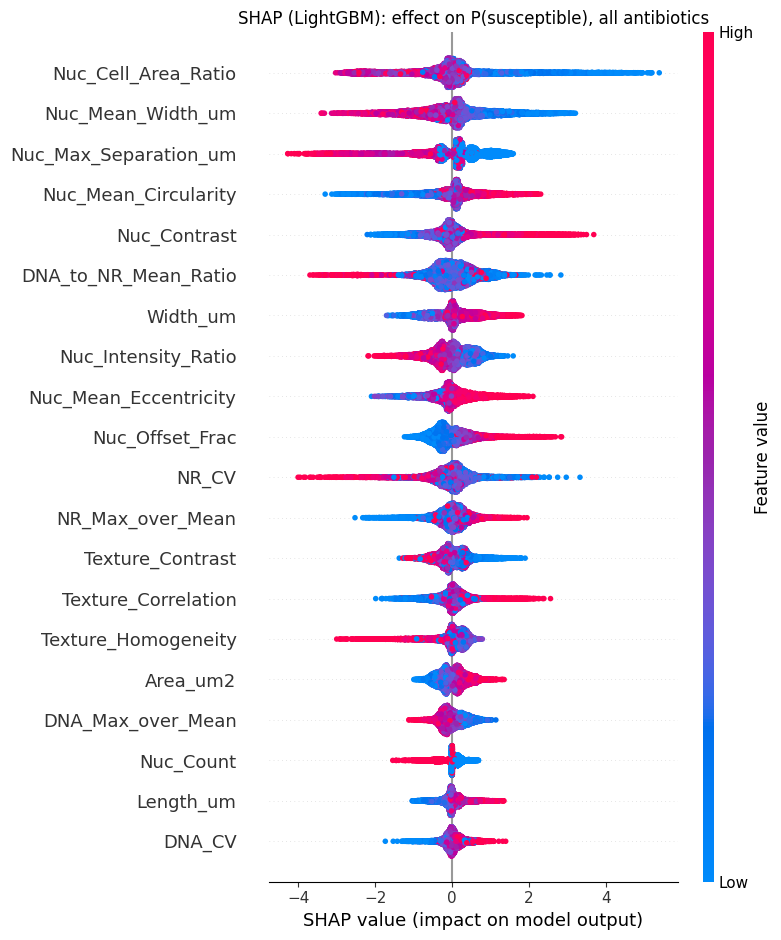

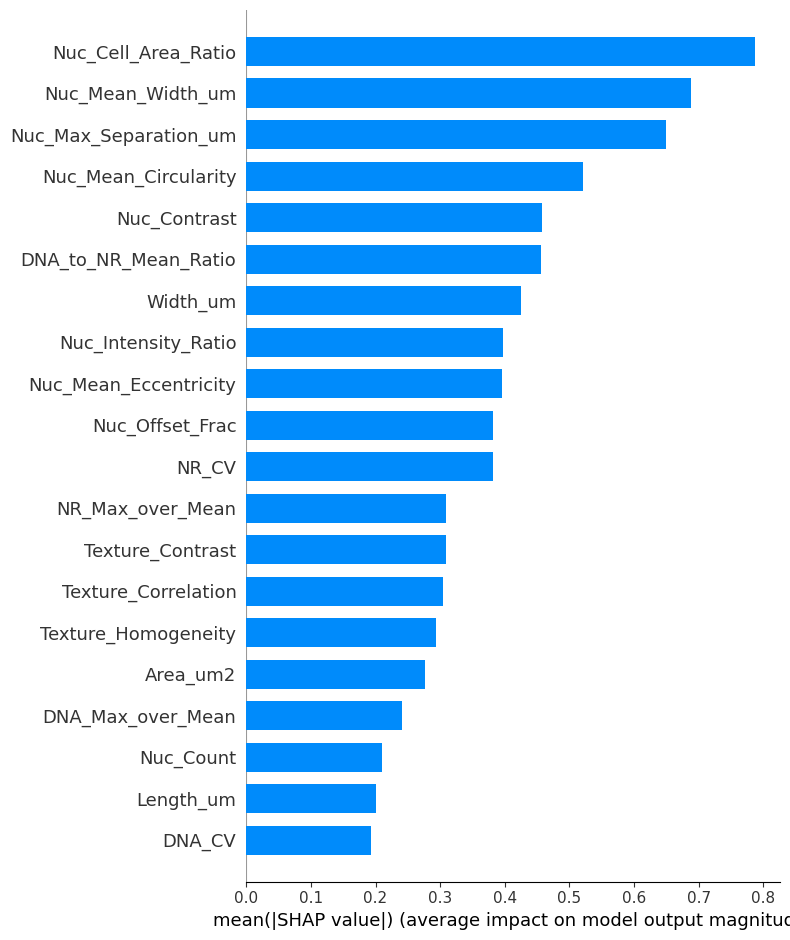

In [116]:
imp_df = pd.DataFrame(imp_by_abx)
imp_df["Mean"] = imp_df.mean(axis=1)
imp_df = imp_df.sort_values("Mean", ascending=False)
imp_df.to_csv(ML / "metrics" / "permutation_importance.csv")
imp = imp_df["Mean"]
display(imp_df.head(12).round(4))
if shap_v:
    sv_all, sx_all = np.vstack(shap_v), pd.concat(shap_x, ignore_index=True)
    plt.figure()
    shap.summary_plot(sv_all, sx_all, show=False, max_display=20)
    plt.title(f"SHAP ({BEST}): effect on P(susceptible), all antibiotics")
    plt.tight_layout()
    plt.savefig(ML / "figures/shap" / "shap_beeswarm.png", dpi=200)
    plt.show()
    plt.figure()
    shap.summary_plot(sv_all, sx_all, plot_type="bar", show=False, max_display=20)
    plt.tight_layout()
    plt.savefig(ML / "figures/shap" / "shap_bar.png", dpi=200)
    plt.show()

**Interpretation:**
* Nucleoid (DNA) features dominate. Each antibiotic has its own signature: CIP depends on nucleoid separation and circularity, RIF on nucleoid width and contrast, GENT on the nucleoid-to-cell area ratio, and COAMOX on the width of the cell itself.
* COAMOX has no single strong feature (the largest value is only 0.05), consistent with it being the hardest class.

**SHAP beeswarm (first figure):**
* Each dot is a cell; position shows how much that feature pushed the prediction towards susceptible (right) or resistant (left), and colour shows the feature value. This reflects what the model learned, not proof of cause.
* A low nucleoid-to-cell area ratio pushes towards susceptible, and a high one towards resistant.
* A large maximum nucleoid separation and a higher nucleoid count push towards resistant. This fits Part A, where WT cells had more nucleoids per cell than CIP and GENT cells.
* A high nucleoid contrast and circularity push towards susceptible, in line with compact, rounded, bright nucleoids in treated cells.

**Second figure:** the SHAP bar chart ranks features by average absolute effect; the top features are the same nucleoid measures.

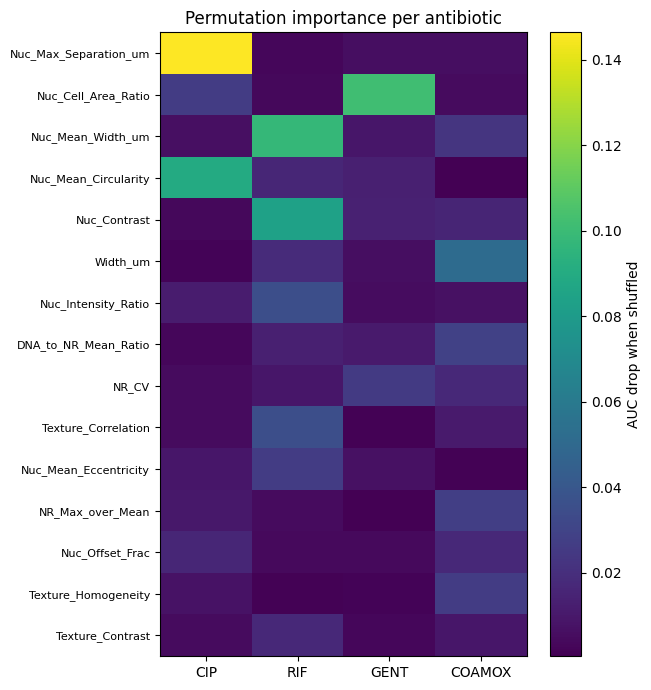

In [117]:
hm = imp_df.drop(columns="Mean").head(15)
fig, ax = plt.subplots(figsize=(6.5, 7))
im = ax.imshow(hm.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(hm.columns)))
ax.set_xticklabels(hm.columns)
ax.set_yticks(range(len(hm)))
ax.set_yticklabels(hm.index, fontsize=8)
fig.colorbar(im, label="AUC drop when shuffled")
ax.set_title("Permutation importance per antibiotic")
fig.tight_layout()
fig.savefig(ML / "figures/shap" / "importance_per_antibiotic.png", dpi=200)
plt.show()

* A heat map of the numbers in In [116], one column per antibiotic.
* The bright cells show the antibiotic-specific features (separation for CIP, width for RIF, area ratio for GENT, cell width for COAMOX).
* A column with no bright cell (COAMOX) means the signal is spread over many features.

In [118]:
ML_BUNDLE = {
    "family": BEST,
    "feature_set": FEATURE_SET,
    "features": FEATS,
    "abx_order": ABX,
    "treat_classes": TREAT,
    "models": sweep[BEST]["pipes"],
    "platt": sweep[BEST]["plat"],
    "treatment_model": tid_ml,
}
joblib.dump(ML_BUNDLE, ML / "models" / "amr_ml_classifier.joblib")
print("saved", ML / "models" / "amr_ml_classifier.joblib")

saved /content/drive/MyDrive/Research/results_final/cellpose_otsu/machine_learning/models/amr_ml_classifier.joblib


The LightGBM pipeline and its metadata are saved as `amr_ml_classifier.joblib`. This artifact is intended for later inference with the same feature schema and preprocessing. Keep the feature list, model version, segmentation configuration and training metadata together when sharing it.

## B5. ML evaluation on the held-out test rows: one plot per metric + grid

In [119]:
overall_ml = binary_metrics(yt, p_ml_te)
per_abx_ml = pd.DataFrame(
    {ab: binary_metrics(yt[Ate == k], p_ml_te[Ate == k]) for k, ab in enumerate(ABX)}
).T

In [120]:
pd.Series(overall_ml).to_csv(ML / "metrics" / "ml_overall.csv")
per_abx_ml.to_csv(ML / "metrics" / "ml_per_antibiotic.csv")
thr_ml = pd.DataFrame(
    [
        {
            "thr": t,
            **{
                k: v
                for k, v in binary_metrics(yt, p_ml_te, t).items()
                if k in ("Accuracy", "Precision", "Recall", "F1")
            },
        }
        for t in np.linspace(0.05, 0.95, 91)
    ]
)

In [121]:
R_ml = dict(
    y=yt,
    p=p_ml_te,
    A=Ate,
    overall=overall_ml,
    per_abx=per_abx_ml,
    thr=thr_ml,
    cm_tid=cm_tid_ml,
    tid_report=tid_report_ml,
    val_auc=val_auc,
    test_tbl=test_tbl,
    cv=cv,
    imp=imp,
)

In [122]:
display(pd.Series(overall_ml).round(4).to_frame(BEST).T)

,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,MCC,Kappa,ROC_AUC,PR_AUC,Brier,LogLoss,ECE,TP,FP,TN,FN
LightGBM,0.8993,0.886,0.8449,0.8474,0.9245,0.8462,0.7714,0.7714,0.9603,0.931,0.0728,0.2369,0.0146,5894.0,1082.0,13254.0,1061.0


* The selected LightGBM model achieves accuracy 0.8993, balanced accuracy 0.8860, precision 0.8449, recall 0.8474, specificity 0.9245, F1 0.8462, MCC 0.7714, kappa 0.7714 and ROC-AUC about 0.960.
* Compared with DenseNet121's binary test accuracy (0.8505) and F1 (0.8040), the tabular model performs better on several thresholded metrics in this run.
* Compare confidence intervals and calibration measures as well; a single point estimate is not enough to conclude a statistically reliable difference.

In [123]:
display(per_abx_ml.round(3))

,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,MCC,Kappa,ROC_AUC,PR_AUC,Brier,LogLoss,ECE,TP,FP,TN,FN
CIP,0.890,0.886,0.815,0.876,0.897,0.844,0.760,0.759,0.961,0.934,0.077,0.243,0.032,1631.0,370.0,3214.0,231.0
RIF,0.880,0.880,0.863,0.875,0.885,0.869,0.759,0.759,0.951,0.946,0.087,0.285,0.021,2606.0,413.0,3171.0,372.0
GENT,0.951,0.939,0.895,0.913,0.964,0.904,0.871,0.871,0.985,0.966,0.037,0.130,0.014,1094.0,129.0,3455.0,104.0
COAMOX,0.884,0.783,0.768,0.614,0.953,0.682,0.618,0.612,0.924,0.771,0.085,0.272,0.016,563.0,170.0,3414.0,354.0


* This table breaks binary test performance down by antibiotic.
* ROC-AUC, F1, precision, recall and specificity reveal whether performance is consistent across drugs.
* Avoid relying only on an overall average: COAMOX is generally the more difficult treatment group in this notebook, and class-specific trade-offs may be hidden by pooled metrics.

In [124]:
def p_ml_val(ax, R):
    d = R["val_auc"]
    im = ax.imshow(
        d.values, cmap="viridis", vmin=max(0.5, np.nanmin(d.values) - 0.02), vmax=1, aspect="auto"
    )
    for i in range(d.shape[0]):
        for j in range(d.shape[1]):
            ax.text(
                j, i, f"{d.values[i, j]:.3f}", ha="center", va="center", fontsize=8, color="white"
            )
    ax.set_xticks(range(d.shape[1]))
    ax.set_xticklabels(d.columns, fontsize=8)
    ax.set_yticks(range(d.shape[0]))
    ax.set_yticklabels(d.index, fontsize=8)
    ax.set_title("Validation ROC-AUC (model x antibiotic)")

In [125]:
def p_ml_test(ax, R):
    d = R["test_tbl"][["ROC_AUC", "F1", "MCC"]].astype(float)
    x = np.arange(len(d))
    for i, k in enumerate(d.columns):
        ax.bar(x + (i - 1) * 0.27, d[k].values, 0.27, label=k)
    ax.set_xticks(x)
    ax.set_xticklabels(d.index, rotation=35, ha="right", fontsize=8)
    ax.set(ylim=(0, 1.05), title="All models, test set")
    ax.legend(ncol=3, fontsize=8, loc="upper center")
    ax.grid(alpha=0.3, axis="y")

In [126]:
def p_cv(ax, R):
    cv_ = R["cv"]
    if len(cv_) == 0:
        ax.text(0.5, 0.5, "CV not run", ha="center")
        ax.axis("off")
        return
    g = cv_.groupby("abx")[["AUC", "F1", "MCC"]].agg(["mean", "std"]).reindex(ABX)
    for i, k in enumerate(["AUC", "F1", "MCC"]):
        ax.bar(
            np.arange(len(g)) + (i - 1) * 0.27,
            g[(k, "mean")].values,
            0.27,
            yerr=g[(k, "std")].fillna(0).values,
            capsize=3,
            label=k,
        )
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels(ABX)
    ax.set(ylim=(0, 1.1), title=f"Grouped-by-image {CV_FOLDS}-fold CV (mean ± sd)")
    ax.legend(ncol=3, fontsize=8, loc="upper center")
    ax.grid(alpha=0.3, axis="y")

In [127]:
def p_fi(ax, R):
    s = R["imp"].sort_values().tail(15)
    ax.barh(s.index, s.values, color=C_S)
    ax.set(xlabel="mean AUC drop when shuffled", title="Permutation importance (top 15)")
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(alpha=0.3, axis="x")

In [128]:
PLOTS_ML = [
    ("model_validation_auc", p_ml_val),
    ("model_test_scores", p_ml_test),
    ("grouped_cross_validation", p_cv),
    ("confusion_counts", p_cm_counts),
    ("confusion_normalised", p_cm_norm),
    ("roc", p_roc),
    ("precision_recall", p_pr),
    ("calibration", p_calib),
    ("confidence_distribution", p_hist),
    ("scores", p_scores),
    ("per_antibiotic", p_per_abx),
    ("coverage_accuracy", p_cov),
    ("call_composition", p_calls),
    ("threshold_sweep", p_thr),
    ("feature_importance", p_fi),
    ("treatment_confusion", p_tid_cm),
]

In [129]:
for i, (n, f) in enumerate(PLOTS_ML, 1):
    fig, ax = plt.subplots(figsize=(6.5, 5.2))
    f(ax, R_ml)
    fig.tight_layout()
    fig.savefig(ML / "figures/individual" / f"{i:02d}_{n}.png", dpi=200)
    plt.close(fig)

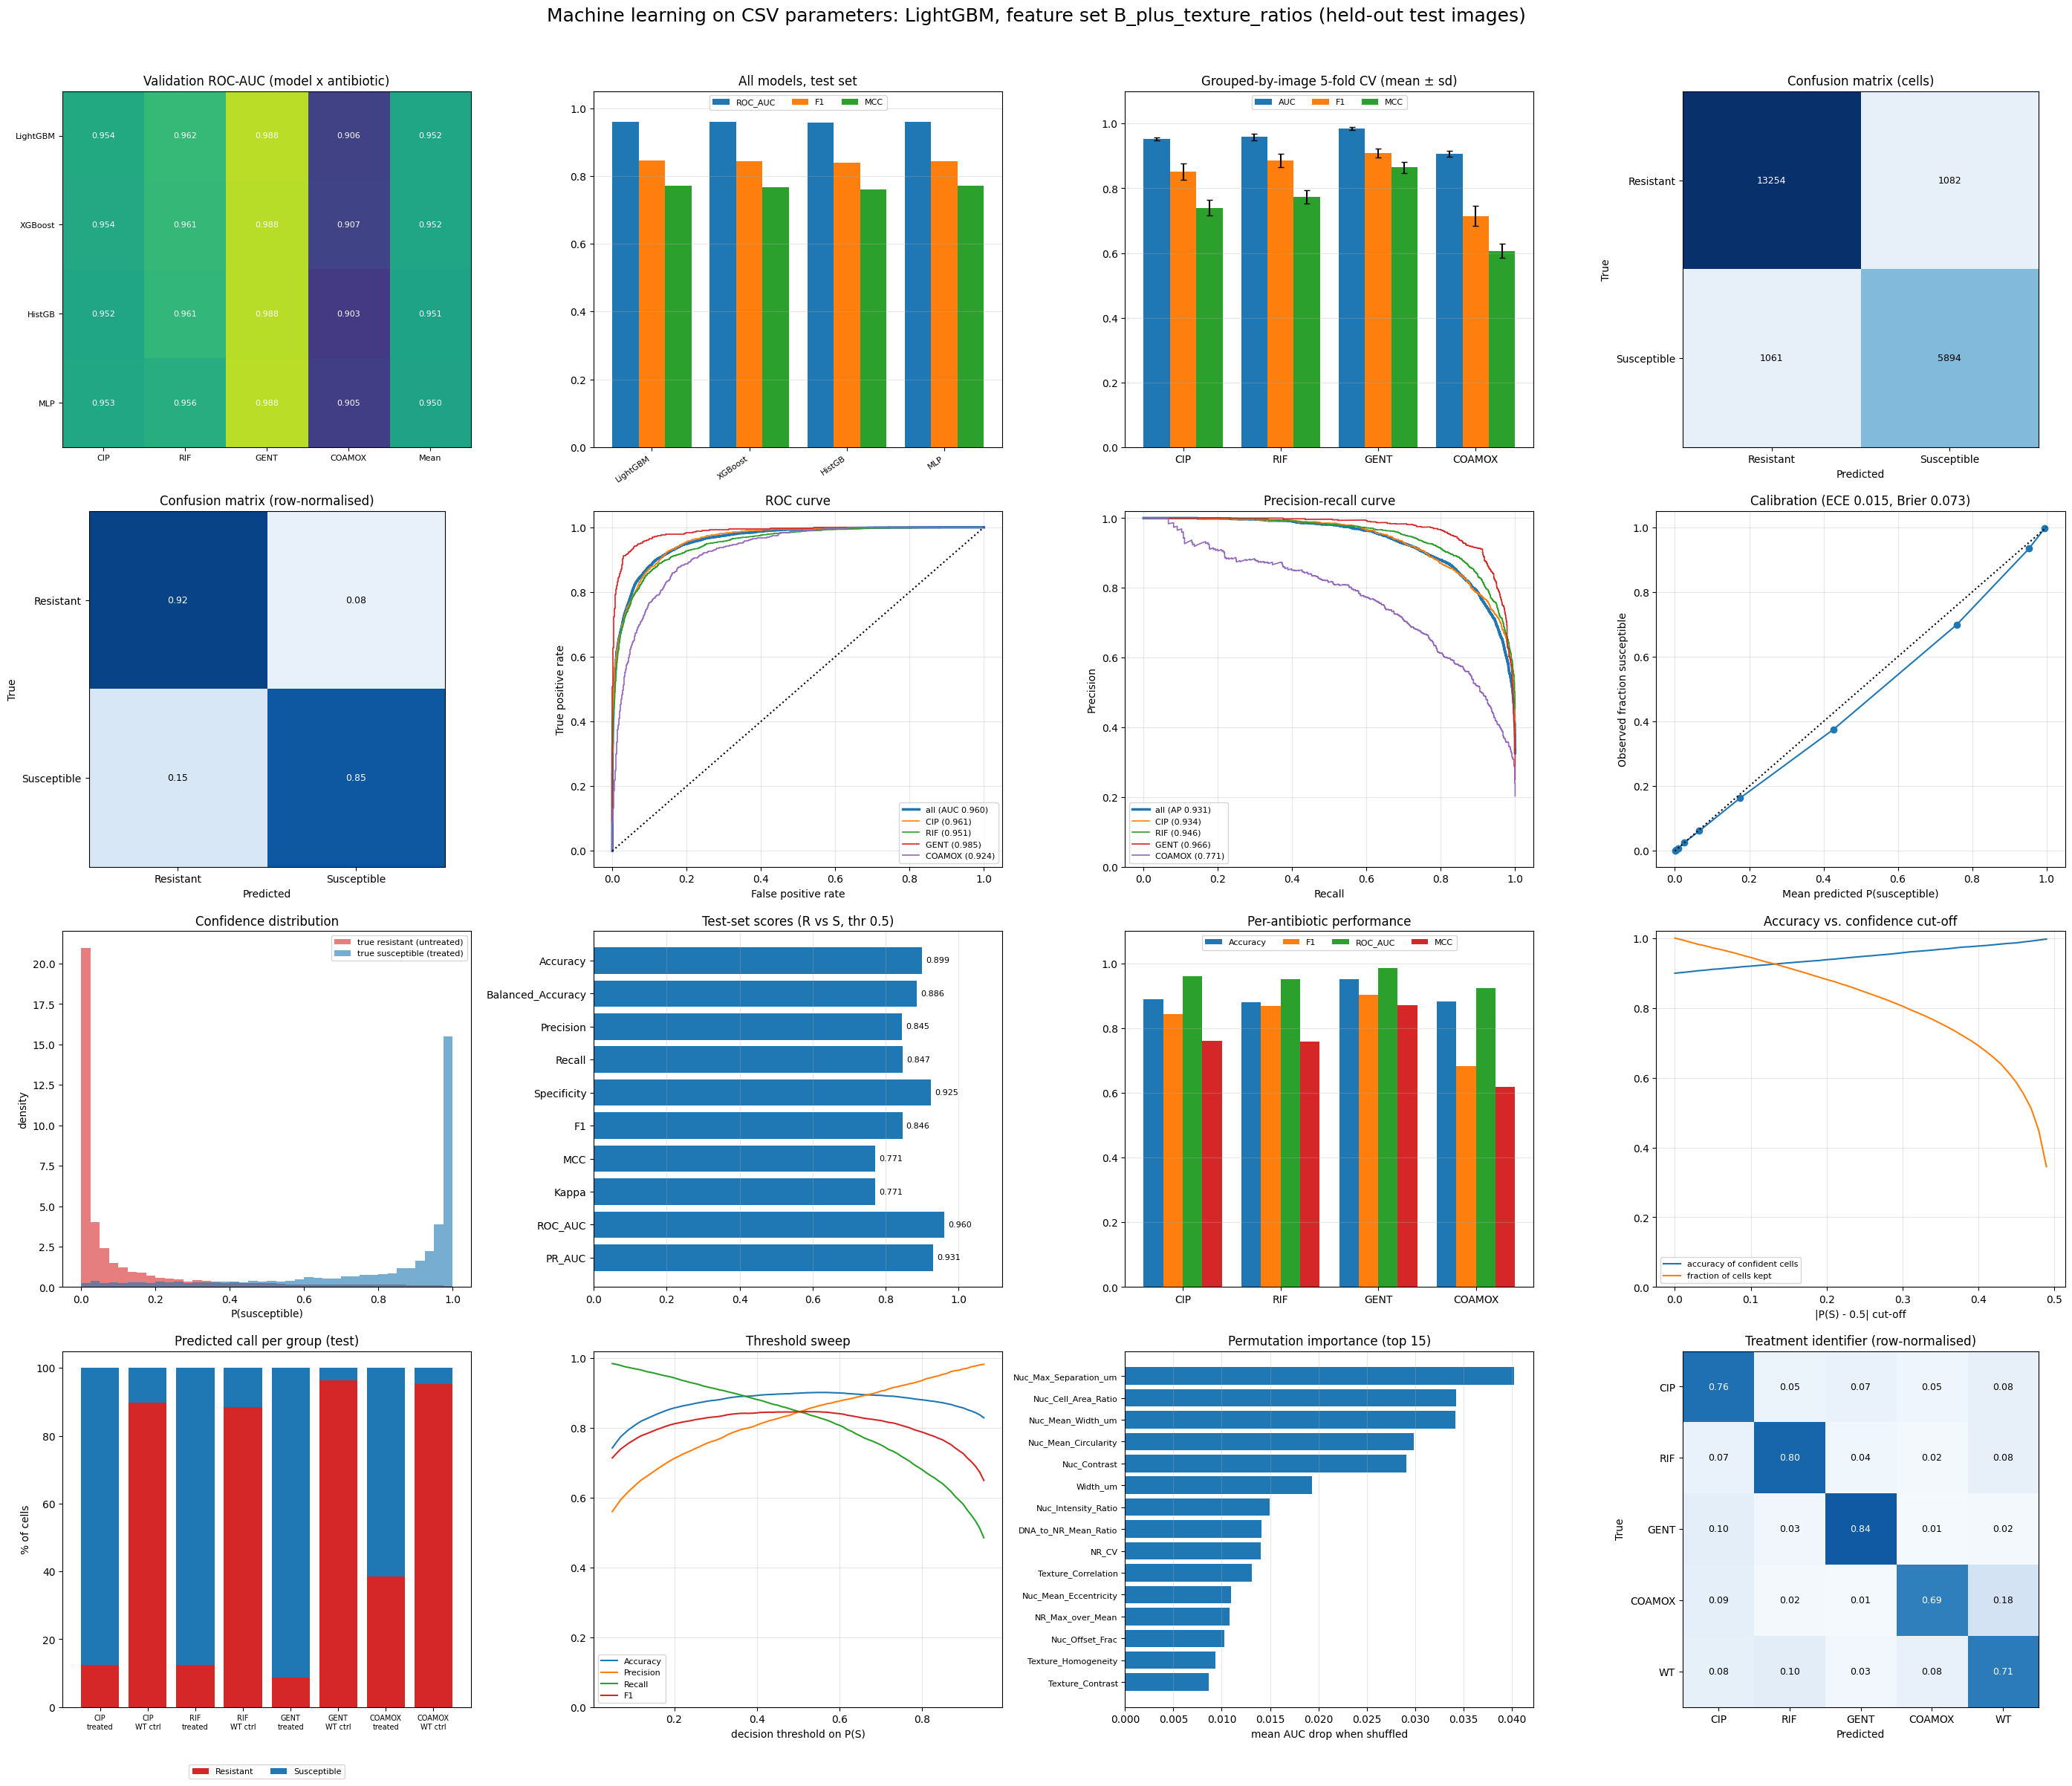

In [130]:
fig = plt.figure(figsize=(28, 24))
for i, (n, f) in enumerate(PLOTS_ML, 1):
    f(fig.add_subplot(4, 4, i), R_ml)
fig.suptitle(
    f"Machine learning on CSV parameters: {BEST}, feature set {FEATURE_SET} (held-out test images)",
    fontsize=18,
    y=0.995,
)
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(ML / "figures" / "ml_evaluation_grid.png", dpi=200)
fig.savefig(ML / "figures" / "ml_evaluation_grid.pdf")
plt.show()

* **Validation AUC heat map and test bars:** the four models are equivalent; GENT is easiest and COAMOX hardest in every model.
* **Grouped CV bars:** small error bars show stable performance (see In [111]).
* **Confusion matrices:** 92% of WT and 85% of treated cells are called correctly.
* **ROC and precision-recall:** per antibiotic, GENT best, COAMOX lowest.
* **Calibration (ECE 0.015):** the curve lies on the diagonal, so probabilities can be read as real probabilities.
* **Confidence distribution:** well separated, with sharp peaks at 0 (WT) and 1 (treated).
* **Accuracy against confidence cut-off and threshold sweep:** accuracy and F1 are flat around a threshold of 0.5, so the default is a good choice for this model.
* **Call composition:** WT controls are called resistant 88% to 96% of the time. Treated cells are called susceptible about 88% (CIP, RIF) to 91% (GENT), but only about 62% for COAMOX.
* **Permutation importance and treatment confusion:** the same findings as In [116] and In [114].

# Part C. Deep learning vs machine learning vs ensemble (identical test rows)
The test rows are the same (cell, antibiotic) pairs for all three. The ensemble is the plain mean of the two calibrated probabilities. Confidence intervals resample whole **images** (cells of one image are not independent). The McNemar test below is cell-level and therefore optimistic; trust the image-bootstrap more.

In [131]:
assert np.array_equal(yt, S["test"][1]) and len(p_te) == len(p_ml_te)
LBL = {"DL": "DenseNet121 (image)", "ML": f"{BEST} (CSV parameters)", "ENS": "Ensemble (mean)"}
COL = {"DL": "#1f77b4", "ML": "#ff7f0e", "ENS": "#2ca02c"}
P = {"DL": p_te, "ML": p_ml_te, "ENS": (p_te + p_ml_te) / 2}
imgs_t = meta.loc[it, "Image_ID"].values
tbl = pd.DataFrame({n: binary_metrics(yt, p) for n, p in P.items()}).T
per = {
    n: pd.DataFrame({ab: binary_metrics(yt[Ate == k], p[Ate == k]) for k, ab in enumerate(ABX)}).T
    for n, p in P.items()
}

In [132]:
grp = {u: np.where(imgs_t == u)[0] for u in np.unique(imgs_t)}
keys = list(grp)
rb = np.random.RandomState(SEED)
boots = {n: [] for n in P}
for _ in range(N_BOOT):
    ii = np.concatenate([grp[keys[j]] for j in rb.choice(len(keys), len(keys))])
    if len(np.unique(yt[ii])) < 2:
        continue
    for n, p in P.items():
        boots[n].append(skm.roc_auc_score(yt[ii], p[ii]))
CI = {n: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for n, v in boots.items()}
tbl["AUC_95CI"] = [f"{CI[n][0]:.3f}-{CI[n][1]:.3f}" for n in tbl.index]

In [133]:
def image_level(p):
    d = (
        pd.DataFrame({"Image_ID": imgs_t, "abx": Ate, "y": yt, "p": p})
        .groupby(["Image_ID", "abx"])
        .agg(y=("y", "first"), frac_S=("p", lambda s: float((s >= 0.5).mean())), n=("p", "size"))
        .reset_index()
    )
    d["pred"] = (d.frac_S >= 0.5).astype(int)
    return d

In [134]:
IMG_L = {n: image_level(p) for n, p in P.items()}
tbl["Image_level_accuracy"] = [float((IMG_L[n].pred == IMG_L[n].y).mean()) for n in tbl.index]
tbl["Images_scored"] = len(IMG_L["DL"])
tbl.rename(index=LBL).to_csv(ML / "metrics" / "dl_vs_ml_comparison.csv")
pd.concat({n: per[n][["Accuracy", "F1", "MCC", "ROC_AUC"]] for n in P}, axis=1).to_csv(
    ML / "metrics" / "dl_vs_ml_per_antibiotic.csv"
)

In [135]:
dl_ok, ml_ok = (p_te >= 0.5) == yt, (p_ml_te >= 0.5) == yt
b_, c_ = int((dl_ok & ~ml_ok).sum()), int((~dl_ok & ml_ok).sum())
mc = (abs(b_ - c_) - 1) ** 2 / max(b_ + c_, 1)
mc_p = float(chi2.sf(mc, 1))
d_auc = np.array(boots["DL"]) - np.array(boots["ML"])
d_ci = (np.percentile(d_auc, 2.5), np.percentile(d_auc, 97.5))

In [136]:
COLS = [
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "MCC",
    "Kappa",
    "ROC_AUC",
    "PR_AUC",
    "Brier",
    "LogLoss",
    "ECE",
    "AUC_95CI",
    "Image_level_accuracy",
]
print("=== TEST SET: deep learning vs machine learning (same cells, same split) ===")
display(tbl.rename(index=LBL)[COLS])
print(
    f"McNemar (cell level, optimistic): DL-only correct = {b_}, ML-only correct = {c_}, p = {mc_p:.3g}"
)
print(
    f"AUC difference DL - ML, image bootstrap 95% CI: [{d_ci[0]:+.4f}, {d_ci[1]:+.4f}] (interval containing 0 = no reliable difference)"
)
print("Per-antibiotic ROC-AUC")
display(pd.DataFrame({LBL[n]: per[n]["ROC_AUC"] for n in P}).round(4))
print(f"Treatment identification, image-level accuracy: DL {img_acc:.3f} | ML {img_acc_ml:.3f}")

=== TEST SET: deep learning vs machine learning (same cells, same split) ===


,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,MCC,Kappa,ROC_AUC,PR_AUC,Brier,LogLoss,ECE,AUC_95CI,Image_level_accuracy
DenseNet121 (image),0.850547,0.873216,0.703221,0.938605,0.807826,0.804040,0.705949,0.687216,0.954513,0.920140,0.106400,0.343175,0.131505,0.941-0.969,0.920273
LightGBM (CSV parameters),0.899347,0.885987,0.844897,0.847448,0.924526,0.846170,0.771376,0.771374,0.960334,0.930994,0.072828,0.236894,0.014551,0.952-0.968,0.961276
Ensemble (mean),0.915128,0.916175,0.836999,0.919195,0.913156,0.876174,0.813889,0.811827,0.975137,0.956930,0.069233,0.238231,0.085522,0.967-0.982,0.974943


McNemar (cell level, optimistic): DL-only correct = 1392, ML-only correct = 2431, p = 2.99e-63
AUC difference DL - ML, image bootstrap 95% CI: [-0.0156, +0.0063] (interval containing 0 = no reliable difference)
Per-antibiotic ROC-AUC


,DenseNet121 (image),LightGBM (CSV parameters),Ensemble (mean)
CIP,0.9591,0.9610,0.9777
RIF,0.9409,0.9505,0.9694
GENT,0.9864,0.9854,0.9936
COAMOX,0.9048,0.9240,0.9386


Treatment identification, image-level accuracy: DL 0.919 | ML 0.936


**Interpretation**
* The AUC difference DL minus ML has a 95% bootstrap interval of [-0.016, +0.006]. It contains 0, so there is no reliable difference in ranking quality between the image model and the parameter model.
* The lower accuracy and F1 of the DL model at a 0.5 threshold come mainly from its over-calling of "susceptible" (see In [78]), not from a worse ability to separate the classes.
* The McNemar test (DL-only correct 1,392 cells, ML-only correct 2,431, p = 3e-63) is at the cell level, where cells of one image are not independent, so it is optimistic. Rely on the image-level bootstrap more.
* The ensemble beats both single models on every ranking and overall metric (AUC 0.975, MCC 0.814) and has the best image-level accuracy (0.975), so combining the two views is worthwhile.
* Calibration: ML is best (ECE 0.015). The ensemble inherits part of the DL miscalibration (ECE 0.086).

* Per-antibiotic AUC (DL / ML / ensemble): CIP 0.959 / 0.961 / 0.978, RIF 0.941 / 0.951 / 0.969, GENT 0.986 / 0.985 / 0.994, COAMOX 0.905 / 0.924 / 0.939. Image-level treatment identification: DL 0.919, ML 0.936.

In [137]:
CMP = {"P": P, "y": yt, "A": Ate, "tbl": tbl, "per": per, "img": IMG_L, "ci": CI}

def c_roc(ax, C):
    for n, p in C["P"].items():
        f, t, _ = skm.roc_curve(C["y"], p)
        ax.plot(
            f,
            t,
            color=COL[n],
            lw=2,
            label=f"{LBL[n]}  AUC {C['tbl'].loc[n, 'ROC_AUC']:.3f} [{C['ci'][n][0]:.3f}-{C['ci'][n][1]:.3f}]",
        )
    ax.plot([0, 1], [0, 1], "k:")
    ax.set(
        xlabel="False positive rate",
        ylabel="True positive rate",
        title="ROC (95% CI by image bootstrap)",
    )
    ax.legend(fontsize=7, loc="lower right")
    ax.grid(alpha=0.3)

In [138]:
def c_pr(ax, C):
    for n, p in C["P"].items():
        pr, rc, _ = skm.precision_recall_curve(C["y"], p)
        ax.plot(rc, pr, color=COL[n], lw=2, label=f"{LBL[n]}  AP {C['tbl'].loc[n, 'PR_AUC']:.3f}")
    ax.set(xlabel="Recall", ylabel="Precision", title="Precision-recall", ylim=(0, 1.02))
    ax.legend(fontsize=7, loc="lower left")
    ax.grid(alpha=0.3)

In [139]:
def c_bars(ax, C):
    ks = [
        "Accuracy",
        "Balanced_Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1",
        "MCC",
        "ROC_AUC",
    ]
    x = np.arange(len(ks))
    for i, n in enumerate(C["P"]):
        ax.bar(
            x + (i - 1) * 0.27,
            C["tbl"].loc[n, ks].astype(float).values,
            0.27,
            color=COL[n],
            label=LBL[n],
        )
    ax.set_xticks(x)
    ax.set_xticklabels([k.replace("_", "\n") for k in ks], fontsize=7)
    ax.set(ylim=(0, 1.1), title="Test-set metrics")
    ax.legend(fontsize=7, loc="upper center", ncol=1)
    ax.grid(alpha=0.3, axis="y")

In [140]:
def c_abx(ax, C):
    for i, n in enumerate(C["P"]):
        ax.bar(
            np.arange(len(ABX)) + (i - 1) * 0.27,
            C["per"][n]["ROC_AUC"].astype(float).values,
            0.27,
            color=COL[n],
            label=LBL[n],
        )
    ax.set_xticks(range(len(ABX)))
    ax.set_xticklabels(ABX)
    ax.set(ylim=(0.5, 1.03), title="ROC-AUC per antibiotic")
    ax.legend(fontsize=7, loc="lower center")
    ax.grid(alpha=0.3, axis="y")

In [141]:
def c_img(ax, C):
    for i, n in enumerate(C["P"]):
        d = C["img"][n]
        a0, a1 = d.loc[d.y == 0, "frac_S"].values, d.loc[d.y == 1, "frac_S"].values
        for pos, v in ((i - 0.22 + 0.0, a0), (i + 0.22, a1)):
            if len(v):
                ax.boxplot(
                    [v],
                    positions=[pos],
                    widths=0.35,
                    patch_artist=True,
                    showfliers=True,
                    boxprops=dict(facecolor=COL[n], alpha=0.6),
                    medianprops=dict(color="k"),
                )
    ax.set_xticks(range(len(C["P"])))
    ax.set_xticklabels(
        [f"{n}\nacc {(C['img'][n].pred == C['img'][n].y).mean():.2f}" for n in C["P"]], fontsize=8
    )
    ax.axhline(0.5, color="k", ls=":")
    ax.set(
        ylabel="fraction of cells called susceptible",
        title="Image-level readout (left box = WT, right box = treated)",
        ylim=(-0.02, 1.02),
    )
    ax.grid(alpha=0.3, axis="y")

In [142]:
def c_cal(ax, C):
    for n, p in C["P"].items():
        fr, mp = calibration_curve(C["y"], p, n_bins=10, strategy="quantile")
        ax.plot(mp, fr, "o-", color=COL[n], label=f"{LBL[n]} (ECE {C['tbl'].loc[n, 'ECE']:.3f})")
    ax.plot([0, 1], [0, 1], "k:")
    ax.set(xlabel="Mean predicted P(susceptible)", ylabel="Observed fraction", title="Calibration")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

In [143]:
def c_cm(ax, C, n):
    c = skm.confusion_matrix(C["y"], (C["P"][n] >= 0.5).astype(int), labels=[0, 1]).astype(float)
    _cm(
        ax,
        c / c.sum(1, keepdims=True),
        ["Resistant", "Susceptible"],
        f"{LBL[n]}\n(row-normalised)",
        frac=True,
    )

In [144]:
PLOTS_CMP = [
    ("roc_overlay", c_roc),
    ("pr_overlay", c_pr),
    ("metric_bars", c_bars),
    ("per_antibiotic_auc", c_abx),
    ("image_level_fraction_S", c_img),
    ("calibration_overlay", c_cal),
    ("confusion_DL", lambda ax, C: c_cm(ax, C, "DL")),
    ("confusion_ML", lambda ax, C: c_cm(ax, C, "ML")),
    ("confusion_ENS", lambda ax, C: c_cm(ax, C, "ENS")),
]

In [145]:
(ML / "figures" / "comparison").mkdir(exist_ok=True)
for i, (n, f) in enumerate(PLOTS_CMP, 1):
    fig, ax = plt.subplots(figsize=(6.5, 5.2))
    f(ax, CMP)
    fig.tight_layout()
    fig.savefig(ML / "figures/comparison" / f"{i:02d}_{n}.png", dpi=200)
    plt.close(fig)

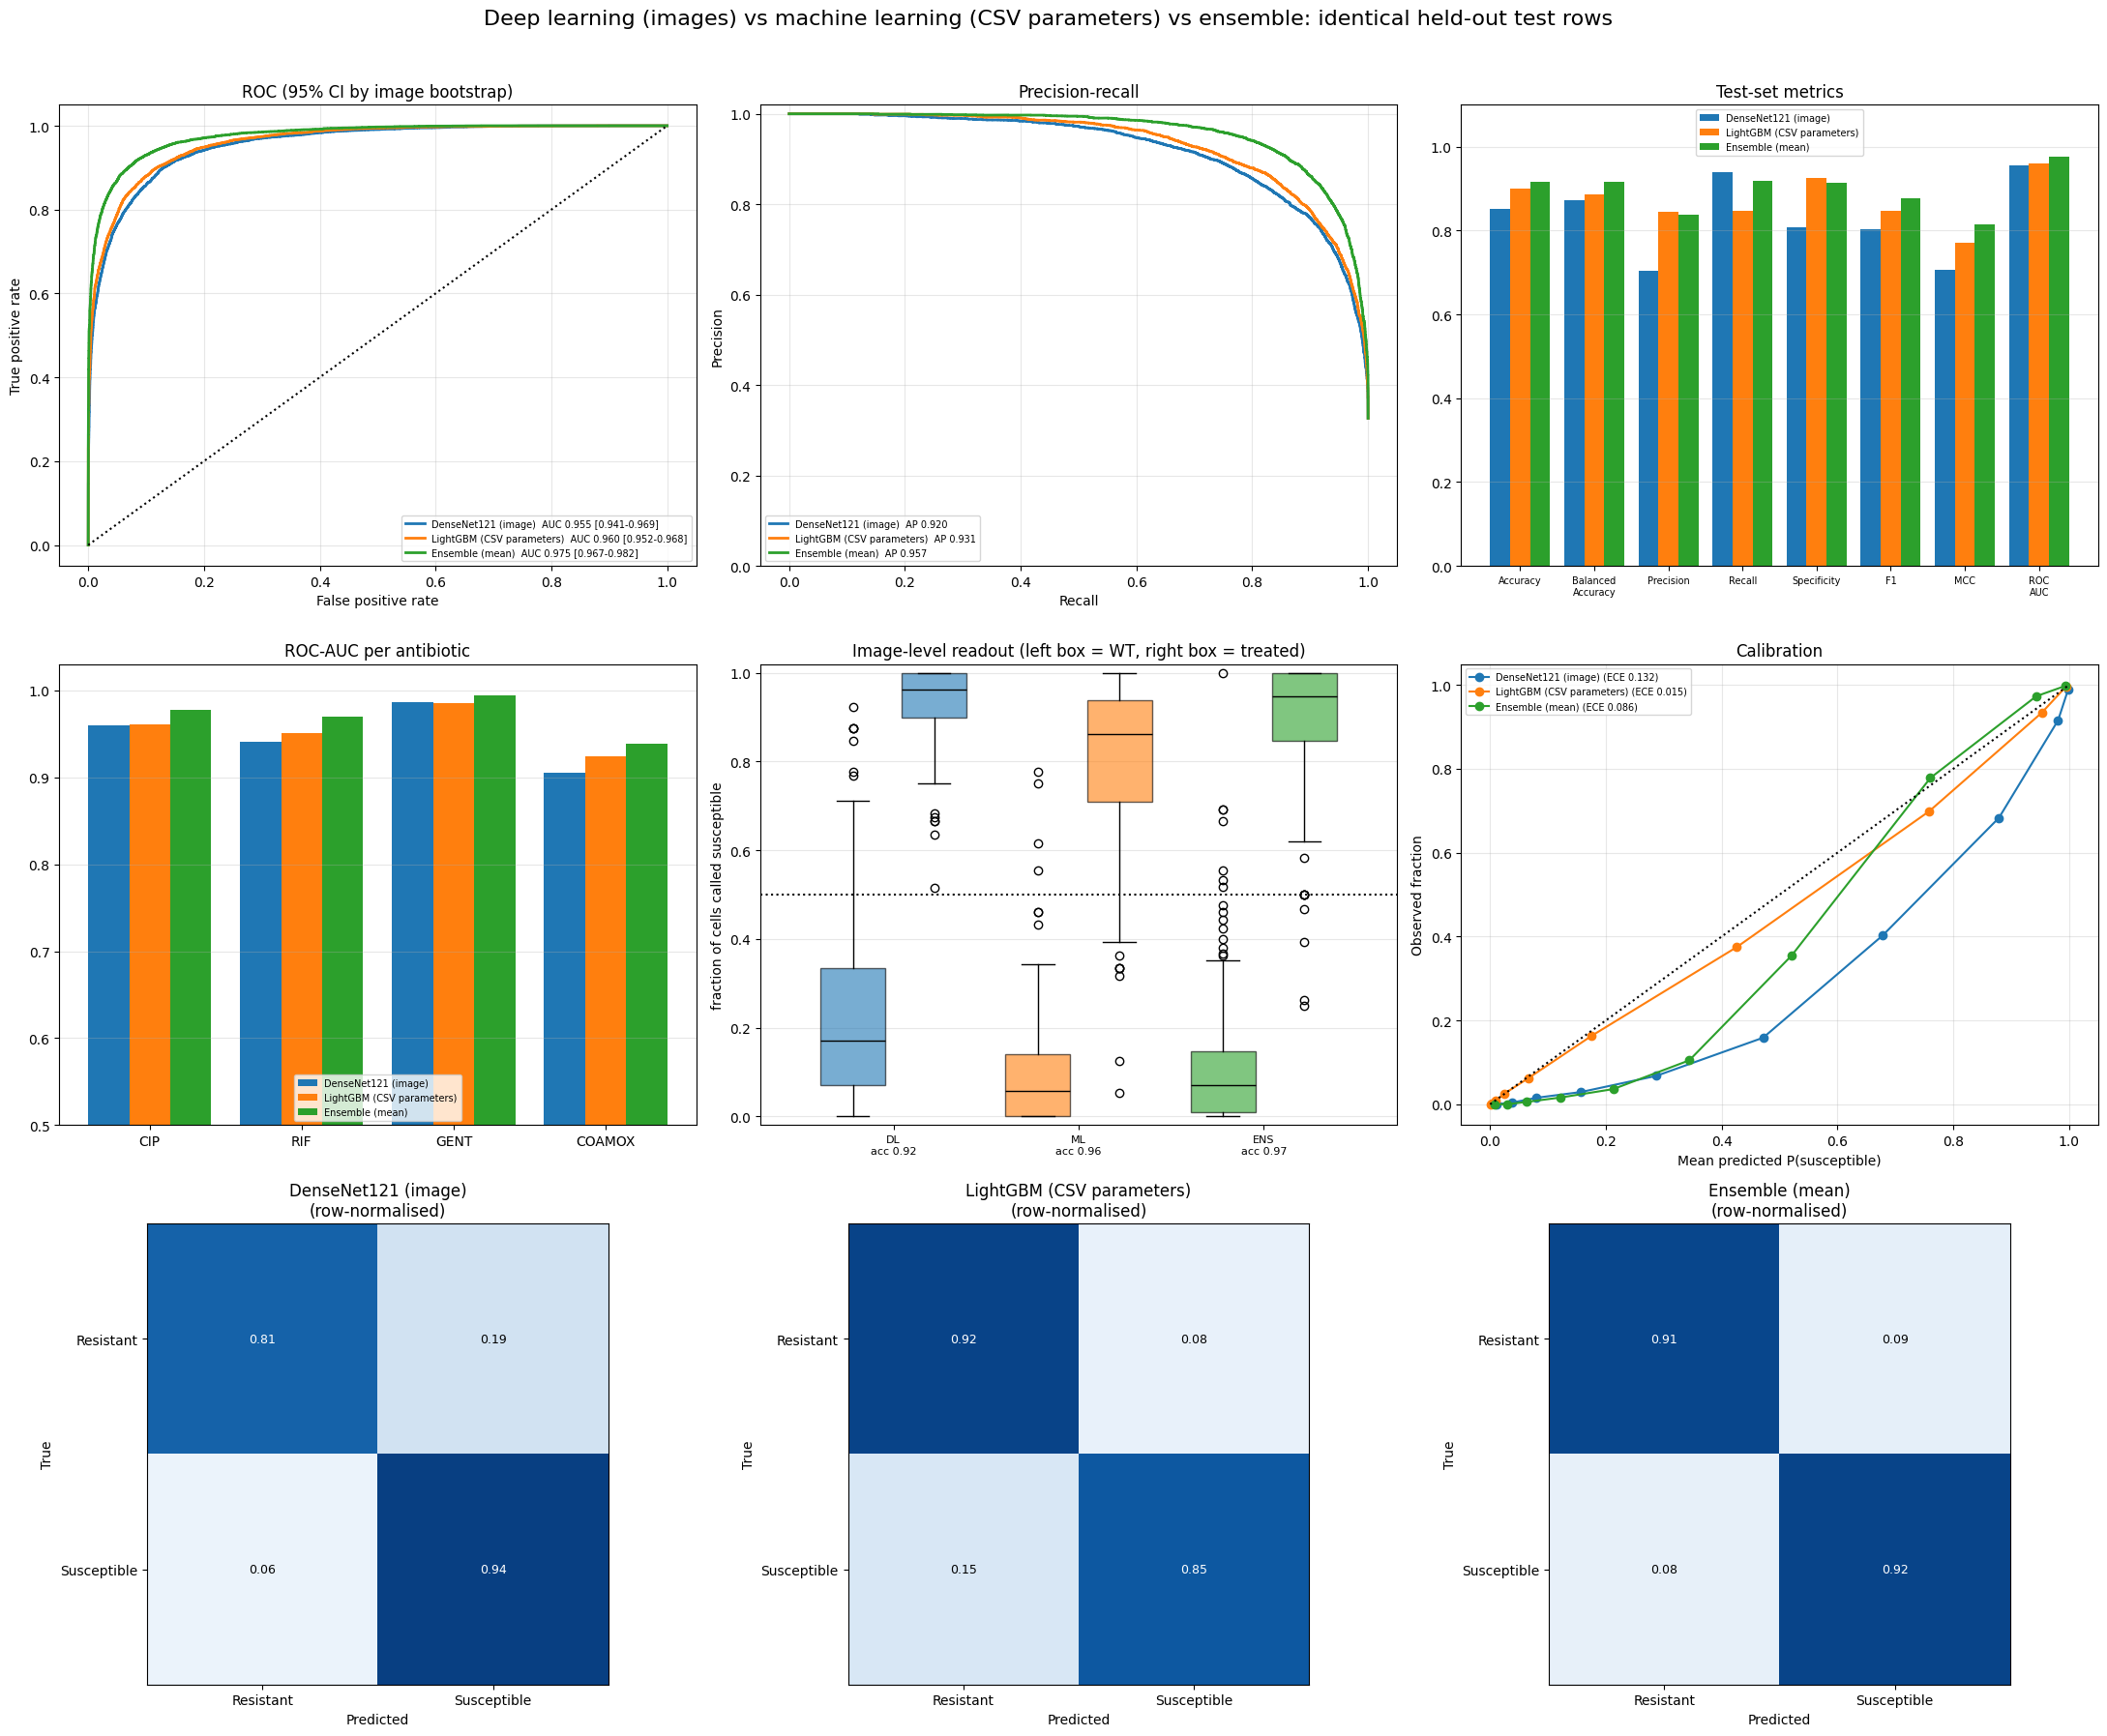

In [146]:
fig = plt.figure(figsize=(22, 18))
for i, (n, f) in enumerate(PLOTS_CMP, 1):
    f(fig.add_subplot(3, 3, i), CMP)
fig.suptitle(
    "Deep learning (images) vs machine learning (CSV parameters) vs ensemble: identical held-out test rows",
    fontsize=16,
    y=0.995,
)
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(ML / "figures" / "dl_vs_ml_grid.png", dpi=200)
fig.savefig(ML / "figures" / "dl_vs_ml_grid.pdf")
plt.show()

**Interpretation**
* **ROC overlay:** the DL and ML curves are close; the ensemble is clearly higher (95% intervals shown).
* **Precision-recall overlay:** same ranking (AP 0.920, 0.931, 0.957).
* **Metric bars:** the DL model wins on recall but loses on precision and specificity; ML is balanced; the ensemble is highest overall.
* **Per-antibiotic AUC:** ensemble best in all four; all models are weakest on COAMOX.
* **Image-level readout (left box = WT, right box = treated):** 
    - for each image, the fraction of cells called susceptible. A good model keeps WT images below the dotted 0.5 line and treated images above it. The DL model's WT images have a median of about 0.17 with a long upper tail (some WT images cross 0.5), while the ML and ensemble medians are about 0.05 to 0.07. Treated images are above 0.5 for nearly all images, with a median of about 0.95 for DL and the ensemble.
* **Calibration overlay:** the ML curve follows the diagonal; DL is below it; the ensemble lies in between.
* **Confusion matrices:** DL catches 94% of susceptible cells but wrongly flags 19% of WT cells; ML is more balanced (92% / 85%); the ensemble reaches 91% / 92%.

# Part D. Inference: upload an image -> parameters -> treatment -> DL + ML + ensemble (Resistant / Susceptible %)
`featurize_image` recomputes **exactly the CSV parameters** (same functions as `process_image`). The first cell below checks this on a training image against `cells_all.csv`.

In [147]:
# Raw images are only needed here (demo + consistency check). Extract them now, not at the start of the notebook.
def _ok(p):
    return not p.name.startswith("._") and "__MACOSX" not in p.parts
RAW_DIR.mkdir(exist_ok=True)
if not any(RAW_DIR.iterdir()):
    with zipfile.ZipFile(RAW_ZIP) as z:
        z.extractall(RAW_DIR)
INPUT_DIR = [p.parent for p in RAW_DIR.rglob(CLASSES[0]) if p.is_dir() and _ok(p)][0]
images = {c: sorted(p for p in (INPUT_DIR / c).glob("*.tif*") if _ok(p)) for c in CLASSES}
print({c: len(v) for c, v in images.items()})

{'CIP+ETOH': 285, 'RIF+ETOH': 279, 'GENT+ETOH': 199, 'COAMOX+ETOH': 350, 'WT+ETOH': 455}


In [148]:
def featurize_image(path):
    arr = load_raw(path)
    H, W = arr.shape[:2]
    membrane, dna = arr[..., 0].astype(np.float32), arr[..., 1].astype(np.float32)
    cm = clean_labels(segment_cells(normalize_channel(membrane), DIAMETER, FLOW), MIN_CELL_AREA_PX)
    nm = segment_nucleoids_otsu(cm, dna)
    crops, rows = [], []
    for cell in regionprops(cm):
        r0, c0, r1, c1 = cell.bbox
        y0, x0, y1, x1 = (
            max(0, r0 - CROP_MARGIN),
            max(0, c0 - CROP_MARGIN),
            min(H, r1 + CROP_MARGIN),
            min(W, c1 + CROP_MARGIN),
        )
        win = (slice(y0, y1), slice(x0, x1))
        sub_cell = cm[win] == cell.label
        sub_memb, sub_dna = membrane[win], dna[win]
        crops.append(prep_cell(np.moveaxis(arr[win][..., :2], -1, 0), sub_cell))
        sub_nuc = np.where(sub_cell, nm[win], 0)
        a = float(cell.area)
        lp, wp = float(cell.major_axis_length), float(cell.minor_axis_length)
        row = {
            "Cell_Label": int(cell.label),
            "Area_um2": a * UM2,
            "Length_um": lp * PIXEL_SIZE_UM,
            "Width_um": wp * PIXEL_SIZE_UM,
            "Perimeter_um": float(cell.perimeter) * PIXEL_SIZE_UM,
            "Aspect_Ratio": lp / wp if wp > 0 else np.nan,
            "Circularity": circularity(a, cell.perimeter),
            "Eccentricity": float(cell.eccentricity),
            "Solidity": float(cell.solidity),
            "Extent": float(cell.extent),
            "Touches_Border": bool(r0 == 0 or c0 == 0 or r1 == H or c1 == W),
        }
        row.update(intensity_stats(sub_memb[sub_cell], "NileRed_Intensity"))
        row.update(intensity_stats(sub_dna[sub_cell], "DNA_Intensity"))
        row.update(glcm_features(sub_memb, sub_cell))
        row.update(
            nucleoid_summary(
                regionprops(sub_nuc, intensity_image=sub_dna),
                sub_nuc,
                sub_cell,
                sub_dna,
                cell,
                a,
                y0,
                x0,
            )
        )
        row["QC_Pass"] = not (
            row["Touches_Border"]
            or row["Area_um2"] < QC_MIN_AREA_UM2
            or row["Area_um2"] > QC_MAX_AREA_UM2
        )
        rows.append(row)
    return (
        arr,
        cm,
        (np.stack(crops) if crops else np.zeros((0, IMG, IMG, 3), np.uint8)),
        add_derived(pd.DataFrame(rows)),
    )

In [ ]:
def check_feature_consistency():
    """Re-featurize one training image and compare with cells_all.csv (guards against train/inference parameter drift)."""
    src_ = {p.stem: p for v in images.values() for p in v}
    name = str(np.random.RandomState(SEED).choice(meta.Image_ID.unique()))
    _, _, _, f_new = featurize_image(src_[name])
    f_old = feat[feat.Image_ID == name].set_index("Cell_Label")[
        FEATURE_SETS["C_plus_raw_intensity"]
    ]
    f_new = f_new.set_index("Cell_Label")[FEATURE_SETS["C_plus_raw_intensity"]]
    common = f_old.index.intersection(f_new.index)
    if len(common) == 0:
        print("consistency check: no common cells (segmentation differs); skipped")
        return
    rel = (
        (f_new.loc[common] - f_old.loc[common]).abs() / (f_old.loc[common].abs() + 1e-9)
    ).to_numpy()
    rel = rel[np.isfinite(rel)]
    print(
        f"consistency check on {name}: {len(common)} cells matched, median relative difference {np.median(rel):.2e}, 99th percentile {np.percentile(rel, 99):.2e}"
    )
    if np.percentile(rel, 99) > 1e-3:
        print(
            "WARNING: inference parameters differ from the CSV; check that DIAMETER/FLOW and the code versions are the same as in Segmentation Part."
        )


check_feature_consistency()

100%|██████████| 25.3M/25.3M [00:00<00:00, 29.4MB/s]


consistency check on 200818_1_MG1655_NA_AMR_combined_1_WT+ETOH_posXY3: 61 cells matched, median relative difference 0.00e+00, 99th percentile 7.56e-16


In [150]:
def load_inference_models():
    cfgj = json.loads((DL / "models" / "amr_inference_config.json").read_text())
    return (
        keras.models.load_model(DL / "models" / "amr_susceptibility_model.keras"),
        keras.models.load_model(DL / "models" / "amr_treatment_identifier.keras"),
        joblib.load(ML / "models" / "amr_ml_classifier.joblib"),
        cfgj,
    )


def draw_overlay(arr, cm, label_by_cell):
    g = np.clip(
        0.5 * normalize_channel(arr[..., 0].astype(np.float32))
        + 0.5 * normalize_channel(arr[..., 1].astype(np.float32)),
        0,
        1,
    )
    rgb = np.stack([g] * 3, -1)
    lut = np.full((cm.max() + 1, 3), 0.6)
    col = {0: (1, 0, 0), 1: (0, 0.5, 1)}
    for lab, k in label_by_cell.items():
        lut[lab] = col[k]
    b = find_boundaries(cm, mode="inner") & (cm > 0)
    rgb[b] = lut[cm[b]]
    return (rgb * 255).astype(np.uint8)

In [151]:
_INF = {}


def analyse_image(path, antibiotic=None, primary="ENS", save=True, show=True):
    """path -> treatment detection (DL + ML), then R/S percentages from DL, ML and their mean (ENS).
    antibiotic: force CIP/RIF/GENT/COAMOX if known (more reliable than detection). primary: which call colours the overlay.
    """
    if not _INF:
        _INF.update(zip(["sus", "tid", "ml", "cfg"], load_inference_models()))
    sus_m, tid_m, mlb, cfgj = (_INF[k] for k in ("sus", "tid", "ml", "cfg"))
    fcols = mlb["features"]
    arr, cm, crops, feats = featurize_image(path)
    if len(crops) == 0:
        return {"error": "no cells segmented"}
    use = feats.QC_Pass.values if feats.QC_Pass.any() else np.ones(len(feats), bool)
    Xf = feats.loc[use, fcols].astype(float).values
    ncell = int(use.sum())
    p_dl_t = tid_m.predict({"image": crops[use]}, verbose=0, batch_size=256).mean(0)
    p_ml_t = mlb["treatment_model"].predict_proba(Xf).mean(0)
    pt = (p_dl_t + p_ml_t) / 2
    cls = mlb["treat_classes"]
    detected = cls[int(pt.argmax())]
    out = {
        "image": Path(path).name,
        "cells_segmented": len(feats),
        "cells_analysed": ncell,
        "treatment_detected": detected,
        "treatment_confidence_%": {c: round(100 * float(p), 1) for c, p in zip(cls, pt)},
        "treatment_confidence_DL_%": {c: round(100 * float(p), 1) for c, p in zip(cls, p_dl_t)},
        "treatment_confidence_ML_%": {c: round(100 * float(p), 1) for c, p in zip(cls, p_ml_t)},
    }
    if pt.max() < 0.6:
        out["warning"] = "treatment identification is uncertain; pass antibiotic=... if you know it"
    abx = antibiotic or detected
    if abx == cfgj["control_class"]:
        out["note"] = (
            "Detected as untreated (WT) control: no antibiotic phenotype to assess. Pass antibiotic='CIP' etc. to force a susceptibility call."
        )
        print(out)
        return out
    k = mlb["abx_order"].index(abx)
    ab_oh = np.eye(len(mlb["abx_order"]), dtype="float32")[np.full(ncell, k)]
    p_dl = sigmoid(
        logit(sus_m.predict({"image": crops[use], "abx": ab_oh}, verbose=0, batch_size=256).ravel())
        / cfgj["temperature"]
    )
    p_ml = platt_apply(mlb["platt"][k], mlb["models"][abx].predict_proba(Xf)[:, 1])
    pp = {"DL": p_dl, "ML": p_ml, "ENS": (p_dl + p_ml) / 2}
    names = ["Resistant", "Susceptible"]
    cells = feats[use].reset_index(drop=True)[["Cell_Label"] + MORPH + NUC[:3]].copy()
    for n, p in pp.items():
        cells[f"P_susceptible_{n}"] = p
    cells["Call"] = [names[int(v >= 0.5)] for v in pp[primary]]
    out.update(
        {
            "antibiotic_used": abx,
            "cell_fraction_%": {
                n: {
                    "Resistant": round(100 * float((p < 0.5).mean()), 1),
                    "Susceptible": round(100 * float((p >= 0.5).mean()), 1),
                }
                for n, p in pp.items()
            },
            "mean_confidence_%": {
                n: {
                    "Resistant": round(100 * float((1 - p).mean()), 1),
                    "Susceptible": round(100 * float(p.mean()), 1),
                }
                for n, p in pp.items()
            },
        }
    )
    out["overall_call"] = max(
        out["cell_fraction_%"][primary], key=out["cell_fraction_%"][primary].get
    )
    out["cells"] = cells
    ov = draw_overlay(
        arr, cm, {int(l): int(v >= 0.5) for l, v in zip(cells.Cell_Label, pp[primary])}
    )
    out["overlay"] = ov
    if save:
        Image.fromarray(ov).save(ML / "predictions" / f"{Path(path).stem}_RS.png")
        cells.to_csv(ML / "predictions" / f"{Path(path).stem}_cells.csv", index=False)
    print(
        f"{out['image']}: treatment={detected} ({out['treatment_confidence_%'][detected]}%) | antibiotic used={abx} | cells={ncell}"
    )
    print(pd.DataFrame(out["cell_fraction_%"]).T.rename_axis("cells called (%)").to_string())
    print(pd.DataFrame(out["mean_confidence_%"]).T.rename_axis("mean confidence (%)").to_string())
    print("overall call (", primary, "):", out["overall_call"])
    if show:
        plt.figure(figsize=(8, 8))
        plt.imshow(ov)
        plt.axis("off")
        plt.title("red = resistant, blue = susceptible, grey = excluded (border/size)")
        plt.show()
    return out

220914_1_MG1655_NA_AMR_combined_1_GENT+ETOH_posXY7.tif: treatment=GENT (71.0%) | antibiotic used=GENT | cells=54
                  Resistant  Susceptible
cells called (%)                        
DL                      3.7         96.3
ML                      7.4         92.6
ENS                     5.6         94.4
                     Resistant  Susceptible
mean confidence (%)                        
DL                         4.8         95.2
ML                        11.8         88.2
ENS                        8.3         91.7
overall call ( ENS ): Susceptible


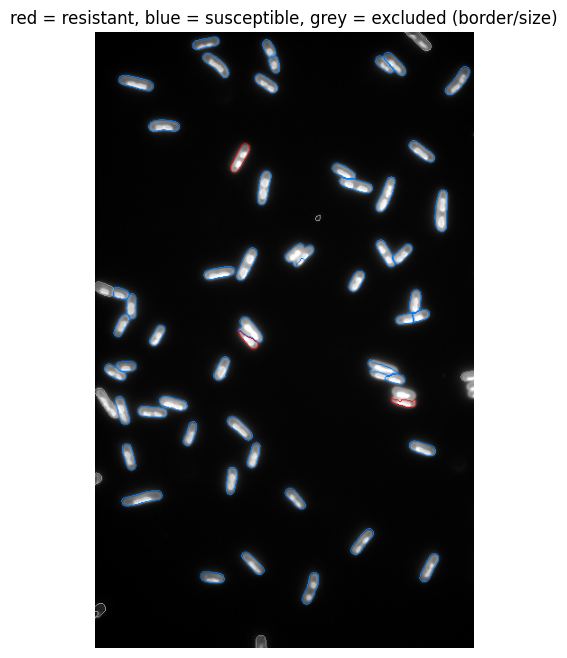

In [152]:
test_imgs = meta.loc[meta.Split == "test", "Image_ID"].unique()
src = {p.stem: p for v in images.values() for p in v}
demo = analyse_image(src[str(np.random.RandomState(SEED).choice(test_imgs))])
# Upload your own image in Colab:
#   from google.colab import files; up = files.upload(); res = analyse_image(list(up)[0])
#   res = analyse_image("/path/to/image.tif", antibiotic="CIP")      # optional: force the antibiotic

* The treatment was identified correctly as GENT (71% confidence), using the average of the DL and ML identifiers. Pass antibiotic="GENT" if you know it, because identification is less reliable than the known label.
* **Cells called susceptible:** DL 96.3%, ML 92.6%, ensemble 94.4%. Overall call: susceptible, which is correct for this image.
* **Overlay colours:** blue outlines are cells called susceptible, red outlines are cells called resistant, and grey are excluded cells (border or size filter). Only a handful of cells are red, which matches the 94% susceptible fraction.

# Part E. Final results summary and download bundle

In [ ]:
print("=" * 78)
print("FINAL RESULTS (held-out test images; identical cells for every model)")
print("=" * 78)
summ = tbl.rename(index=LBL)[
    ["Accuracy", "Balanced_Accuracy", "F1", "MCC", "ROC_AUC", "AUC_95CI", "Image_level_accuracy"]
]
display(summ)
summ.to_csv(ML / "metrics" / "final_summary.csv")
print(f"Deep learning : DenseNet121 on 64x64 two-channel cell crops (Part A)")
print(
    f"Machine learning: {BEST} on {len(FEATS)} CSV parameters (feature set {FEATURE_SET}), chosen on validation ROC-AUC"
)
print(f"Treatment identification (image-level accuracy): DL {img_acc:.3f}, ML {img_acc_ml:.3f}")
print(
    "Interpretation checklist: (1) a CI on the DL-ML AUC difference that contains 0 means no reliable difference; (2) if every model is near 1.0, suspect batch effects between class folders and test on a held-out experiment;"
)
print(
    "(3) image-level accuracy mirrors the paper's population readout; (4) COAMOX is expected to be hardest."
)

FINAL RESULTS (held-out test images; identical cells for every model)


,Accuracy,Balanced_Accuracy,F1,MCC,ROC_AUC,AUC_95CI,Image_level_accuracy
DenseNet121 (image),0.850547,0.873216,0.804040,0.705949,0.954513,0.941-0.969,0.920273
LightGBM (CSV parameters),0.899347,0.885987,0.846170,0.771376,0.960334,0.952-0.968,0.961276
Ensemble (mean),0.915128,0.916175,0.876174,0.813889,0.975137,0.967-0.982,0.974943


Deep learning : DenseNet121 on 64x64 two-channel cell crops (Part B)
Machine learning: LightGBM on 29 CSV parameters (feature set B_plus_texture_ratios), chosen on validation ROC-AUC
Treatment identification (image-level accuracy): DL 0.919, ML 0.936
Interpretation checklist: (1) a CI on the DL-ML AUC difference that contains 0 means no reliable difference; (2) if every model is near 1.0, suspect batch effects between class folders and test on a held-out experiment;
(3) image-level accuracy mirrors the paper's population readout; (4) COAMOX is expected to be hardest.


In [154]:
from google.colab import files
B = Path("/content/final_bundle")
shutil.rmtree(B, ignore_errors=True)
B.mkdir()
for sub in ["tables", "metrics", "figures"]:
    shutil.copytree(OUT_ROOT / sub, B / sub)
for f in ["run_configuration.json", "README.txt"]:
    shutil.copy(OUT_ROOT / f, B / f)
shutil.copytree(DL, B / "deep_learning", ignore=shutil.ignore_patterns("cache"))
shutil.copytree(ML, B / "machine_learning")
shutil.make_archive("/content/amr_final_bundle", "zip", B)
files.download("/content/amr_final_bundle.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>